In [184]:
import pandas as pd
import numpy as numpy
import os


In [185]:
data_path = "data/raw/"

In [186]:
files = os.listdir(data_path)

print("Total files:", len(files))
print(files)

Total files: 28
['01_customer_master.csv', '02_loan_application.csv', '03_income_employment.csv', '04_bureau_data.csv', '05_existing_obligations.csv', '06_collateral_property.csv', '07_kyc_fraud_check.csv', '08_underwriting_decision.csv', '09_disbursement.csv', '10_loan_account_master.csv', '11_monthly_account_performance.csv', '12_delinquency_history.csv', '13_payment_history.csv', '14_account_balance_history.csv', '15_customer_behavior.csv', '16_behavioral_score.csv', '17_portfolio_segment.csv', '18_restructure_forbearance.csv', '19_delinquent_account.csv', '20_collection_case.csv', '21_contact_history.csv', '22_promise_to_pay.csv', '23_collection_payment.csv', '24_agent_performance.csv', '25_collection_strategy.csv', '26_legal_recovery.csv', '27_settlement_write_off.csv', '28_recovery_history.csv']


In [187]:
customer = pd.read_csv(data_path + "01_customer_master.csv")

In [188]:
customer.head()

,CUSTOMER_ID,DOB,AGE,GENDER,MARITAL_STATUS,EDUCATION,OCCUPATION,EMPLOYMENT_TYPE,CITY,STATE,PINCODE,CUSTOMER_SINCE
0,CUST000001,1984-08-23,42,F,MARRIED,POST_GRADUATE,EMPLOYEE,SALARIED,JAIPUR,RJ,564009,2023-03-12
1,CUST000002,1985-09-19,41,F,SINGLE,DIPLOMA,EMPLOYEE,SALARIED,DELHI,DL,449681,2021-03-12
2,CUST000003,1993-10-08,33,M,MARRIED,OTHER,EMPLOYEE,SALARIED,JODHPUR,RJ,284061,2018-07-28
3,CUST000004,1978-08-23,48,M,MARRIED,GRADUATE,EMPLOYEE,SALARIED,KOLKATA,WB,589187,2024-04-20
4,CUST000005,1988-01-07,38,F,MARRIED,POST_GRADUATE,EMPLOYEE,SALARIED,AHMEDABAD,GJ,276268,2020-03-03


In [189]:
customer.shape

(100000, 12)

In [190]:
customer["CUSTOMER_ID"].nunique()

100000

In [191]:
customer["CUSTOMER_ID"].duplicated().sum()

np.int64(0)

In [192]:
customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   CUSTOMER_ID      100000 non-null  str  
 1   DOB              100000 non-null  str  
 2   AGE              100000 non-null  int64
 3   GENDER           100000 non-null  str  
 4   MARITAL_STATUS   100000 non-null  str  
 5   EDUCATION        100000 non-null  str  
 6   OCCUPATION       100000 non-null  str  
 7   EMPLOYMENT_TYPE  100000 non-null  str  
 8   CITY             100000 non-null  str  
 9   STATE            100000 non-null  str  
 10  PINCODE          100000 non-null  int64
 11  CUSTOMER_SINCE   100000 non-null  str  
dtypes: int64(2), str(10)
memory usage: 9.2 MB


In [193]:
customer.isnull().sum()

CUSTOMER_ID        0
DOB                0
AGE                0
GENDER             0
MARITAL_STATUS     0
EDUCATION          0
OCCUPATION         0
EMPLOYMENT_TYPE    0
CITY               0
STATE              0
PINCODE            0
CUSTOMER_SINCE     0
dtype: int64

In [194]:
# this shows the distribution of the gender column in the customer dataset
customer.describe()

,AGE,PINCODE
count,100000.000000,100000.000000
mean,39.118780,504700.789650
std,9.227257,227499.726764
min,21.000000,110005.000000
25%,33.000000,308191.750000
50%,39.000000,504585.000000
75%,45.000000,701428.000000
max,68.000000,899995.000000


In [195]:
customer["GENDER"].value_counts()

GENDER
M    67079
F    32921
Name: count, dtype: int64

In [196]:
customer["MARITAL_STATUS"].value_counts()
customer["EDUCATION"].value_counts()
customer["OCCUPATION"].value_counts()
customer["EMPLOYMENT_TYPE"].value_counts()

EMPLOYMENT_TYPE
SALARIED         61954
SELF_EMPLOYED    23975
GOVT              8183
PROFESSIONAL      5888
Name: count, dtype: int64

In [197]:
customer["CUSTOMER_SINCE"].head()


0    2023-03-12
1    2021-03-12
2    2018-07-28
3    2024-04-20
4    2020-03-03
Name: CUSTOMER_SINCE, dtype: str

In [198]:
customer["CUSTOMER_SINCE"].dtype


<StringDtype(storage='python', na_value=nan)>

In [199]:
# As the customer since is in object format, we will convert it to datetime format for better understanding of the data.
customer["CUSTOMER_SINCE"] = pd.to_datetime(customer["CUSTOMER_SINCE"])

In [200]:
customer["CUSTOMER_SINCE"].dtype

dtype('<M8[us]')

In [201]:
# As the customer DOB   is in object format, we will convert it to datetime format for better understanding of the data.
customer["DOB"] = pd.to_datetime(customer["DOB"])

In [202]:
#this confirms the conversion of the DOB column to datetime format
customer["DOB"].dtype

dtype('<M8[us]')

In [203]:
application = pd.read_csv(
    data_path + "02_loan_application.csv"
)

In [204]:
application.head()

,APPLICATION_ID,CUSTOMER_ID,APPLICATION_DATE,LOAN_TYPE,REQUESTED_AMOUNT,TENURE_MONTHS,LOAN_PURPOSE,CHANNEL,BRANCH_ID,PRODUCT_CODE,APPLICATION_STATUS
0,APP000001,CUST000001,2025-10-21,AUTO_LOAN,831000.0,60,VEHICLE_PURCHASE,BRANCH,BR0211,AL,APPROVED
1,APP000002,CUST000002,2025-08-08,PERSONAL_LOAN,422000.0,36,PERSONAL_USE,BRANCH,BR0289,PL,APPROVED
2,APP000003,CUST000003,2024-08-28,AUTO_LOAN,945000.0,60,VEHICLE_PURCHASE,BRANCH,BR0076,AL,APPROVED
3,APP000004,CUST000004,2025-05-24,AUTO_LOAN,1090000.0,60,VEHICLE_PURCHASE,BRANCH,BR0310,AL,APPROVED
4,APP000005,CUST000005,2026-06-18,HOME_LOAN,4417000.0,240,HOME_PURCHASE,DSA,BR0069,HL,APPROVED


In [205]:
application.shape

(100000, 11)

In [206]:
application.describe()

,REQUESTED_AMOUNT,TENURE_MONTHS
count,1.000000e+05,100000.000000
mean,2.431023e+06,118.689240
std,2.786986e+06,109.019841
min,5.000000e+04,12.000000
25%,6.350000e+05,36.000000
50%,1.212000e+06,60.000000
75%,3.379000e+06,240.000000
max,3.000000e+07,360.000000


In [207]:
application.isnull().sum()

APPLICATION_ID        0
CUSTOMER_ID           0
APPLICATION_DATE      0
LOAN_TYPE             0
REQUESTED_AMOUNT      0
TENURE_MONTHS         0
LOAN_PURPOSE          0
CHANNEL               0
BRANCH_ID             0
PRODUCT_CODE          0
APPLICATION_STATUS    0
dtype: int64

In [208]:
application.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   APPLICATION_ID      100000 non-null  str    
 1   CUSTOMER_ID         100000 non-null  str    
 2   APPLICATION_DATE    100000 non-null  str    
 3   LOAN_TYPE           100000 non-null  str    
 4   REQUESTED_AMOUNT    100000 non-null  float64
 5   TENURE_MONTHS       100000 non-null  int64  
 6   LOAN_PURPOSE        100000 non-null  str    
 7   CHANNEL             100000 non-null  str    
 8   BRANCH_ID           100000 non-null  str    
 9   PRODUCT_CODE        100000 non-null  str    
 10  APPLICATION_STATUS  100000 non-null  str    
dtypes: float64(1), int64(1), str(9)
memory usage: 8.4 MB


In [209]:
application["APPLICATION_ID"].nunique()

100000

In [210]:
application["APPLICATION_ID"].duplicated().sum()

np.int64(0)

In [211]:
application["CUSTOMER_ID"].nunique()

100000

In [212]:
application["APPLICATION_DATE"] = pd.to_datetime(
    application["APPLICATION_DATE"]
)

In [213]:
application["APPLICATION_DATE"].dtype

dtype('<M8[us]')

In [214]:
# This step is we need to ensure that our features come before the future default period.
print("First application date:", application["APPLICATION_DATE"].min())
print("Last application date:", application["APPLICATION_DATE"].max())

First application date: 2023-09-02 00:00:00
Last application date: 2026-08-01 00:00:00


In [215]:
#we have almost 3 years of origination data.
#if we're building a 12-month PD, an application from August 2026 would need future performance through roughly August 2027.

In [216]:
application.describe()


,APPLICATION_DATE,REQUESTED_AMOUNT,TENURE_MONTHS
count,100000,1.000000e+05,100000.000000
mean,2025-02-15 23:33:11.232000,2.431023e+06,118.689240
min,2023-09-02 00:00:00,5.000000e+04,12.000000
25%,2024-05-24 00:00:00,6.350000e+05,36.000000
50%,2025-02-16 00:00:00,1.212000e+06,60.000000
75%,2025-11-11 00:00:00,3.379000e+06,240.000000
max,2026-08-01 00:00:00,3.000000e+07,360.000000
std,NaN,2.786986e+06,109.019841


In [217]:
application["LOAN_TYPE"].value_counts()

LOAN_TYPE
HOME_LOAN         34857
PERSONAL_LOAN     30117
AUTO_LOAN         24983
OVERDRAFT_LOAN    10043
Name: count, dtype: int64

In [218]:
application["APPLICATION_STATUS"].value_counts()

APPLICATION_STATUS
APPROVED                    78622
APPROVED_WITH_CONDITIONS    21378
Name: count, dtype: int64

In [219]:
application["LOAN_PURPOSE"].value_counts()


LOAN_PURPOSE
HOME_PURCHASE       34857
PERSONAL_USE        30117
VEHICLE_PURCHASE    24983
WORKING_CAPITAL     10043
Name: count, dtype: int64

In [220]:
application["CHANNEL"].value_counts()

CHANNEL
DIGITAL    37959
BRANCH     28092
DSA        24020
RM          9929
Name: count, dtype: int64

In [221]:
application["PRODUCT_CODE"].value_counts()


PRODUCT_CODE
HL    34857
PL    30117
AL    24983
OD    10043
Name: count, dtype: int64

In [222]:
#The counts match exactly, so PRODUCT_CODE, LOAN_TYPE, and LOAN_PURPOSE appear to carry essentially the same product information in this synthetic dataset.
application["BRANCH_ID"].nunique()

400

In [223]:
# there are no obvious branches with extremely few or extremely many applications. That's a good sign that we don't have any outlier branches that could skew our model.
application["BRANCH_ID"].value_counts().describe()

count    400.000000
mean     250.000000
std       16.148434
min      190.000000
25%      238.000000
50%      250.000000
75%      260.000000
max      301.000000
Name: count, dtype: float64

In [224]:
application.dtypes

APPLICATION_ID                   str
CUSTOMER_ID                      str
APPLICATION_DATE      datetime64[us]
LOAN_TYPE                        str
REQUESTED_AMOUNT             float64
TENURE_MONTHS                  int64
LOAN_PURPOSE                     str
CHANNEL                          str
BRANCH_ID                        str
PRODUCT_CODE                     str
APPLICATION_STATUS               str
dtype: object

In [225]:
income = pd.read_csv(data_path + "03_income_employment.csv")

income.head()

,CUSTOMER_ID,MONTHLY_INCOME,ANNUAL_INCOME,EMPLOYMENT_TYPE,EMPLOYMENT_TENURE_MONTHS,COMPANY_TYPE,DESIGNATION,OTHER_INCOME,INCOME_VERIFIED_FLAG
0,CUST000001,35490.0,425880.0,SALARIED,123,PRIVATE,EXECUTIVE,0.0,Y
1,CUST000002,143139.0,1717668.0,SALARIED,191,SME,MANAGER,0.0,Y
2,CUST000003,148716.0,1784592.0,SALARIED,68,GOVERNMENT,MANAGER,0.0,Y
3,CUST000004,171293.0,2055516.0,SALARIED,104,PRIVATE,OWNER,17760.0,Y
4,CUST000005,214289.0,2571468.0,SALARIED,117,GOVERNMENT,MANAGER,19935.0,Y


In [226]:
income.shape

(100000, 9)

In [227]:
income["CUSTOMER_ID"].nunique()

100000

In [228]:
income["CUSTOMER_ID"].duplicated().sum()

np.int64(0)

In [229]:
income.isnull().sum()

CUSTOMER_ID                 0
MONTHLY_INCOME              0
ANNUAL_INCOME               0
EMPLOYMENT_TYPE             0
EMPLOYMENT_TENURE_MONTHS    0
COMPANY_TYPE                0
DESIGNATION                 0
OTHER_INCOME                0
INCOME_VERIFIED_FLAG        0
dtype: int64

In [230]:
income.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   CUSTOMER_ID               100000 non-null  str    
 1   MONTHLY_INCOME            100000 non-null  float64
 2   ANNUAL_INCOME             100000 non-null  float64
 3   EMPLOYMENT_TYPE           100000 non-null  str    
 4   EMPLOYMENT_TENURE_MONTHS  100000 non-null  int64  
 5   COMPANY_TYPE              100000 non-null  str    
 6   DESIGNATION               100000 non-null  str    
 7   OTHER_INCOME              100000 non-null  float64
 8   INCOME_VERIFIED_FLAG      100000 non-null  str    
dtypes: float64(3), int64(1), str(5)
memory usage: 6.9 MB


In [231]:
income.describe()

,MONTHLY_INCOME,ANNUAL_INCOME,EMPLOYMENT_TENURE_MONTHS,OTHER_INCOME
count,100000.000000,1.000000e+05,100000.000000,100000.00000
mean,110870.621700,1.330447e+06,137.488550,2301.42999
std,73545.516207,8.825462e+05,83.555145,6515.01318
min,25000.000000,3.000000e+05,3.000000,0.00000
25%,65053.750000,7.806450e+05,75.000000,0.00000
50%,91682.500000,1.100190e+06,124.000000,0.00000
75%,133201.250000,1.598415e+06,188.000000,0.00000
max,900000.000000,1.080000e+07,420.000000,148142.00000


In [232]:
#MONTHLY_INCOME: ₹25,000 → ₹9,00,000, median ~₹91,683. The maximum is much higher than the median, so this may be right-skewed. We'll formally check skewness and visualize it later.
#ANNUAL_INCOME: ₹3 lakh → ₹1.08 crore. Notice that the values appear consistent with MONTHLY_INCOME × 12. We should explicitly verify that relationship later because two perfectly related variables would be redundant.
#EMPLOYMENT_TENURE_MONTHS: 3 → 420 months, i.e. up to 35 years. That's plausible, but later we'll check whether employment tenure is logically consistent with customer age.
#OTHER_INCOME: median and 75th percentile are both 0, while maximum is ₹1,48,142. So most customers probably have no other income, with a smaller subset having positive values. This is likely strongly right-skewed.

In [233]:
# this is checked as we need to compare the customer table also has the same counts
income["EMPLOYMENT_TYPE"].value_counts()

EMPLOYMENT_TYPE
SALARIED         61954
SELF_EMPLOYED    23975
GOVT              8183
PROFESSIONAL      5888
Name: count, dtype: int64

In [234]:
income["COMPANY_TYPE"].value_counts()

COMPANY_TYPE
PRIVATE       33172
MNC           25094
SME           19986
SELF          11904
GOVERNMENT     9844
Name: count, dtype: int64

In [235]:
income["DESIGNATION"].value_counts()

DESIGNATION
EXECUTIVE         34155
MANAGER           29935
SENIOR_MANAGER    13914
PROFESSIONAL      11985
OWNER             10011
Name: count, dtype: int64

In [236]:
#e won't assume unverified income means higher default. Once our target exists, we'll calculate something like:
income["INCOME_VERIFIED_FLAG"].value_counts()

INCOME_VERIFIED_FLAG
Y    96015
N     3985
Name: count, dtype: int64

In [237]:
#important modelling check: if they're exactly equivalent, including both would provide duplicate information
(income["ANNUAL_INCOME"] == income["MONTHLY_INCOME"] * 12).value_counts()

True    100000
Name: count, dtype: int64

In [238]:
#saw a maximum employment tenure of 420 months = 35 years. Let's check whether anyone has an obviously impossible value such as zero or negative tenure.
(income["EMPLOYMENT_TENURE_MONTHS"] <= 0).sum()

np.int64(0)

In [239]:
#OTHER_INCOME looked strongly skewed. Later, a useful feature might even be something like HAS_OTHER_INCOME, alongside or instead of the raw amount
(income["OTHER_INCOME"] == 0).value_counts()

OTHER_INCOME
True     83980
False    16020
Name: count, dtype: int64

In [240]:
#Check whether there are any negative income values, which would be logically invalid here.
(income[["MONTHLY_INCOME", "ANNUAL_INCOME", "OTHER_INCOME"]] < 0).sum()

MONTHLY_INCOME    0
ANNUAL_INCOME     0
OTHER_INCOME      0
dtype: int64

In [241]:
bureau = pd.read_csv(data_path + "04_bureau_data.csv")

bureau.head()

,CUSTOMER_ID,BUREAU_SCORE,TOTAL_ACTIVE_LOANS,TOTAL_OUTSTANDING,CREDIT_CARD_LIMIT,CREDIT_CARD_UTILIZATION,ENQUIRIES_3M,ENQUIRIES_6M,DELINQUENCIES_12M,WRITE_OFF_HISTORY,OLDEST_TRADE_MONTHS
0,CUST000001,764,3,689560.78,64149.0,0.3023,0,0,1,0,10
1,CUST000002,740,3,2347894.00,354221.0,0.4020,2,4,0,0,106
2,CUST000003,773,0,0.00,0.0,0.0000,0,0,0,0,143
3,CUST000004,751,1,1010910.24,0.0,0.0000,0,0,0,0,132
4,CUST000005,674,1,671182.35,856659.0,0.3283,2,3,1,0,36


In [242]:
bureau.shape

(100000, 11)

In [243]:
bureau["CUSTOMER_ID"].nunique()

100000

In [244]:
bureau["CUSTOMER_ID"].duplicated().sum()

np.int64(0)

In [245]:
bureau.isnull().sum()


CUSTOMER_ID                0
BUREAU_SCORE               0
TOTAL_ACTIVE_LOANS         0
TOTAL_OUTSTANDING          0
CREDIT_CARD_LIMIT          0
CREDIT_CARD_UTILIZATION    0
ENQUIRIES_3M               0
ENQUIRIES_6M               0
DELINQUENCIES_12M          0
WRITE_OFF_HISTORY          0
OLDEST_TRADE_MONTHS        0
dtype: int64

In [246]:
bureau.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   CUSTOMER_ID              100000 non-null  str    
 1   BUREAU_SCORE             100000 non-null  int64  
 2   TOTAL_ACTIVE_LOANS       100000 non-null  int64  
 3   TOTAL_OUTSTANDING        100000 non-null  float64
 4   CREDIT_CARD_LIMIT        100000 non-null  float64
 5   CREDIT_CARD_UTILIZATION  100000 non-null  float64
 6   ENQUIRIES_3M             100000 non-null  int64  
 7   ENQUIRIES_6M             100000 non-null  int64  
 8   DELINQUENCIES_12M        100000 non-null  int64  
 9   WRITE_OFF_HISTORY        100000 non-null  int64  
 10  OLDEST_TRADE_MONTHS      100000 non-null  int64  
dtypes: float64(3), int64(7), str(1)
memory usage: 8.4 MB


In [247]:
#We'll inspect whether bureau scores are in a sensible range, 
#whether utilization exceeds expected bounds, how many enquiries/delinquencies occur, 
#and whether any amounts or counts look suspicious.
bureau.describe()

,BUREAU_SCORE,TOTAL_ACTIVE_LOANS,TOTAL_OUTSTANDING,CREDIT_CARD_LIMIT,CREDIT_CARD_UTILIZATION,ENQUIRIES_3M,ENQUIRIES_6M,DELINQUENCIES_12M,WRITE_OFF_HISTORY,OLDEST_TRADE_MONTHS
count,100000.000000,100000.00000,1.000000e+05,1.000000e+05,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,752.045170,1.79814,9.992138e+05,2.536109e+05,0.274866,0.705640,1.50343,0.311730,0.000750,84.974160
std,54.805215,1.34192,1.234662e+06,2.553657e+05,0.244234,0.840297,1.22615,0.627581,0.027376,46.121978
min,520.000000,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,3.000000
25%,715.000000,1.00000,2.757693e+05,0.000000e+00,0.000000,0.000000,1.00000,0.000000,0.000000,52.000000
50%,752.000000,2.00000,6.545759e+05,2.074025e+05,0.253000,1.000000,1.00000,0.000000,0.000000,84.000000
75%,789.000000,3.00000,1.300445e+06,3.696052e+05,0.451700,1.000000,2.00000,0.000000,0.000000,116.000000
max,900.000000,8.00000,2.492367e+07,1.200000e+06,1.100000,6.000000,9.00000,8.000000,1.000000,298.000000


In [248]:
#BUREAU_SCORE ranges from 520 to 900, with a mean around 752. TOTAL_ACTIVE_LOANS ranges from 0 to 8,
#  and TOTAL_OUTSTANDING reaches about ₹2.49 crore, 
# so we'll later examine its skewness rather than automatically treating large balances as outliers.
#CREDIT_CARD_UTILIZATION is especially interesting: its maximum is 1.10, or 110% utilization 
# if the variable is stored as a ratio. That's not necessarily an error—credit-card balances 
# can exceed sanctioned limits—but later we should see how common utilization above 100% is.
#WRITE_OFF_HISTORY is clearly a binary flag: min 0, max 1, and mean 0.00075. 
# That suggests write-off history is extremely rare—approximately 0.075% of customers.
#Also notice that ENQUIRIES_6M is generally greater than ENQUIRIES_3M, 
# which makes logical sense because 6 months contains the most recent 3-month period.
#  But we should actually test that relationship rather than assume every row is consistent.

In [249]:
(bureau["ENQUIRIES_3M"] > bureau["ENQUIRIES_6M"]).sum()

np.int64(0)

In [250]:
#Check credit-card utilization above 100%, which confirms 82 people have a utilization ratio above 1.0, or 100%. 
# This is plausible, but we should later check whether these customers have higher default rates.
(bureau["CREDIT_CARD_UTILIZATION"] > 1).sum()

np.int64(82)

In [251]:
#WRITE_OFF_HISTORY
bureau["WRITE_OFF_HISTORY"].value_counts()

WRITE_OFF_HISTORY
0    99925
1       75
Name: count, dtype: int64

In [252]:
#WRITE_OFF_HISTORY is a highly imbalanced binary variable
#Even though there are only 75 cases, we should not remove this feature simply because it is rare. 
# Prior write-off history can potentially be a strong risk indicator

In [253]:
#Check prior delinquencies, as it shows people with 6-8 deliquent is less
bureau["DELINQUENCIES_12M"].value_counts().sort_index()

DELINQUENCIES_12M
0    75755
1    18889
2     4148
3      922
4      224
5       51
6        8
7        1
8        2
Name: count, dtype: int64

In [254]:
# more loans are into 1-3 and 6-8 loans are less.
bureau["TOTAL_ACTIVE_LOANS"].value_counts().sort_index()

TOTAL_ACTIVE_LOANS
0    16591
1    29762
2    26755
3    16005
4     7275
5     2591
6      749
7      198
8       74
Name: count, dtype: int64

In [255]:
#TOTAL_ACTIVE_LOANS = 0 as count of customer is 16591 of active loans.
bureau.loc[
    bureau["TOTAL_ACTIVE_LOANS"] == 0,
    "TOTAL_OUTSTANDING"
].describe()

count    16591.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: TOTAL_OUTSTANDING, dtype: float64

In [256]:
#Check credit-card limit vs utilization
#28,099 customers with CREDIT_CARD_LIMIT = 0 also have CREDIT_CARD_UTILIZATION = 0
bureau.loc[
    bureau["CREDIT_CARD_LIMIT"] == 0,
    "CREDIT_CARD_UTILIZATION"
].describe()

count    28099.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: CREDIT_CARD_UTILIZATION, dtype: float64

In [257]:
#bureau score distribution boundaries
#So we have some where around 64% of customers are between 701 and 800. 
# Very low bureau scores are relatively rare in this approved applicant population.
pd.cut(
    bureau["BUREAU_SCORE"],
    bins=[0, 600, 650, 700, 750, 800, 900],
    include_lowest=True
).value_counts().sort_index()

BUREAU_SCORE
(-0.001, 600.0]      316
(600.0, 650.0]      2866
(650.0, 700.0]     14154
(700.0, 750.0]     31624
(750.0, 800.0]     32192
(800.0, 900.0]     18848
Name: count, dtype: int64

In [258]:
bureau["OLDEST_TRADE_MONTHS"].describe()

count    100000.000000
mean         84.974160
std          46.121978
min           3.000000
25%          52.000000
50%          84.000000
75%         116.000000
max         298.000000
Name: OLDEST_TRADE_MONTHS, dtype: float64

In [259]:
obligations = pd.read_csv(
    data_path + "05_existing_obligations.csv"
)

obligations.head()

,CUSTOMER_ID,EXISTING_EMI,TOTAL_MONTHLY_OBLIGATION,TOTAL_SECURED_BALANCE,TOTAL_UNSECURED_BALANCE,DTI,FOIR
0,CUST000001,2759.0,3729.0,180623.49,50330.34,2.4371,0.1051
1,CUST000002,9256.0,16376.0,507422.18,237025.12,2.0684,0.1144
2,CUST000003,30063.0,30063.0,1668539.37,306517.93,0.0000,0.2022
3,CUST000004,45831.0,45831.0,2531195.44,619297.50,0.3426,0.2424
4,CUST000005,58934.0,72997.0,2716851.08,1258635.15,0.2010,0.3117


In [260]:
obligations.shape

(100000, 7)

In [261]:
obligations["CUSTOMER_ID"].nunique()

100000

In [262]:
obligations["CUSTOMER_ID"].duplicated().sum()

np.int64(0)

In [263]:
obligations.isnull().sum()

CUSTOMER_ID                 0
EXISTING_EMI                0
TOTAL_MONTHLY_OBLIGATION    0
TOTAL_SECURED_BALANCE       0
TOTAL_UNSECURED_BALANCE     0
DTI                         0
FOIR                        0
dtype: int64

In [264]:
obligations.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   CUSTOMER_ID               100000 non-null  str    
 1   EXISTING_EMI              100000 non-null  float64
 2   TOTAL_MONTHLY_OBLIGATION  100000 non-null  float64
 3   TOTAL_SECURED_BALANCE     100000 non-null  float64
 4   TOTAL_UNSECURED_BALANCE   100000 non-null  float64
 5   DTI                       100000 non-null  float64
 6   FOIR                      100000 non-null  float64
dtypes: float64(6), str(1)
memory usage: 5.3 MB


In [265]:
#EXISTING_EMI and TOTAL_MONTHLY_OBLIGATION are strongly right-skewed 
# candidates—the maximums are much larger than the medians.
obligations.describe()


,EXISTING_EMI,TOTAL_MONTHLY_OBLIGATION,TOTAL_SECURED_BALANCE,TOTAL_UNSECURED_BALANCE,DTI,FOIR
count,100000.000000,100000.000000,1.000000e+05,1.000000e+05,100000.000000,100000.000000
mean,21243.844610,26081.720120,1.008678e+06,3.305069e+05,0.897034,0.231192
std,23398.155198,25678.211996,1.259664e+06,3.366703e+05,0.787496,0.145819
min,1.000000,3.000000,5.154000e+01,2.176000e+01,0.000000,0.000000
25%,6766.000000,10042.750000,2.690989e+05,1.223441e+05,0.349000,0.120000
50%,14391.000000,18799.500000,6.156402e+05,2.339491e+05,0.705400,0.203400
75%,27404.250000,33325.250000,1.271174e+06,4.225472e+05,1.319900,0.315425
max,554798.000000,585143.000000,3.954323e+07,7.352820e+06,4.000000,0.939800


In [266]:
#A DTI of 1.0 would normally mean debt relative to income of 100% 
# if this dataset uses the conventional ratio definition. So values above 1 deserve investigation.
#  They may be legitimate based on how this synthetic variable was generated, or DTI may use a different definition.
#FOIR ranges from 0 to 0.9398, with median 0.2034. We'll also investigate exactly
#  how it relates to monthly income and obligations.
#This is an important industry lesson: don't assume a variable's formula purely from its column name.
#  We validate it against the underlying data or data dictionary.

In [267]:
#TOTAL_MONTHLY_OBLIGATION >= EXISTING_EMI
(obligations["TOTAL_MONTHLY_OBLIGATION"] < obligations["EXISTING_EMI"]).sum()

np.int64(0)

In [268]:
#FOIR formula
foir_check = (
    obligations["TOTAL_MONTHLY_OBLIGATION"]
    / income["MONTHLY_INCOME"]
)

foir_check.describe()

count    100000.000000
mean          0.236322
std           0.147985
min           0.000047
25%           0.123501
50%           0.208328
75%           0.322332
max           0.980901
dtype: float64

In [269]:
#This cofirms FOIR = TOTAL_MONTHLY_OBLIGATION / MONTHLY_INCOME. but FOIR, but not exactly the same

In [270]:
#Compare them row-by-row
(
    foir_check - obligations["FOIR"]
).abs().describe()

count    100000.000000
mean          0.005151
std           0.017467
min           0.000000
25%           0.000015
50%           0.000030
75%           0.000045
max           0.336864
dtype: float64

In [271]:
#Count the materially different FOIR records, 
# Let's see how many customers have a difference greater than 0.01 (1 percentage point)
(
    (foir_check - obligations["FOIR"]).abs() > 0.01
).sum()

np.int64(12297)

In [272]:
#That's significant: 12,297 customers (12.3%) have a difference greater than 0.01.
#So this is clearly not just rounding. For most records the formula matches closely, 
# but for about 12% something else is happening.

In [273]:
# Fixed Obligation to income ratio. example (if customer is earning 100,000 and has obligations of 20,000(that is his fixed regular deduction),
#  then FOIR = 0.2 or 20%)
foir_diff = (foir_check - obligations["FOIR"]).abs()

obligations.loc[
    foir_diff > 0.01,
    ["CUSTOMER_ID", "TOTAL_MONTHLY_OBLIGATION", "FOIR"]
].head(10)

,CUSTOMER_ID,TOTAL_MONTHLY_OBLIGATION,FOIR
3,CUST000004,45831.0,0.2424
4,CUST000005,72997.0,0.3117
6,CUST000007,60918.0,0.2867
10,CUST000011,46172.0,0.2469
23,CUST000024,9392.0,0.1344
28,CUST000029,36290.0,0.3453
30,CUST000031,86034.0,0.2703
31,CUST000032,41785.0,0.3039
38,CUST000039,10121.0,0.1876
58,CUST000059,20070.0,0.3043


In [274]:
(obligations["DTI"] > 1).sum()

np.int64(35348)

In [275]:
obligations[["DTI", "FOIR"]].corr()

,DTI,FOIR
DTI,1.000000,0.006979
FOIR,0.006979,1.000000


In [276]:
#Check zero balances(how many customers have no secured or unsecured balances)
#In real portfolios, we might expect some borrowers to have only secured debt, only unsecured debt, or neither
(obligations[["TOTAL_SECURED_BALANCE", "TOTAL_UNSECURED_BALANCE"]] == 0).sum()

TOTAL_SECURED_BALANCE      0
TOTAL_UNSECURED_BALANCE    0
dtype: int64

In [277]:
#Check whether obligations contain negative values
(
    obligations[
        [
            "EXISTING_EMI",
            "TOTAL_MONTHLY_OBLIGATION",
            "TOTAL_SECURED_BALANCE",
            "TOTAL_UNSECURED_BALANCE",
            "DTI",
            "FOIR"
        ]
    ] < 0
).sum()

EXISTING_EMI                0
TOTAL_MONTHLY_OBLIGATION    0
TOTAL_SECURED_BALANCE       0
TOTAL_UNSECURED_BALANCE     0
DTI                         0
FOIR                        0
dtype: int64

In [278]:
collateral = pd.read_csv(
    data_path + "06_collateral_property.csv"
)

collateral.head()

,APPLICATION_ID,COLLATERAL_TYPE,PROPERTY_TYPE,PROPERTY_VALUE,VALUATION_DATE,COLLATERAL_VALUE,LOAN_AMOUNT,LTV,PROPERTY_CITY,PROPERTY_AGE_YEARS,LEGAL_CLEARANCE_FLAG
0,APP000001,VEHICLE,HATCHBACK,917719.96,2025-10-13,917099.57,793000.0,0.8647,JAIPUR,2,Y
1,APP000003,VEHICLE,HATCHBACK,1201036.66,2024-08-22,1207662.93,906000.0,0.7502,JODHPUR,2,Y
2,APP000004,VEHICLE,SUV,1575875.24,2025-05-14,1602014.67,1065000.0,0.6648,KOLKATA,2,Y
3,APP000005,PROPERTY,INDEPENDENT_HOUSE,5563927.81,2026-06-09,5410168.19,4254000.0,0.7863,AHMEDABAD,6,Y
4,APP000007,VEHICLE,SEDAN,1576245.47,2024-08-21,1638121.51,1005000.0,0.6135,DELHI,1,Y


In [279]:
print("Shape:", collateral.shape)
print("Unique applications:", collateral["APPLICATION_ID"].nunique())
print("Duplicate application IDs:", collateral["APPLICATION_ID"].duplicated().sum())

Shape: (59840, 11)
Unique applications: 59840
Duplicate application IDs: 0


In [280]:
#Link collateral to loan type
collateral_check = collateral.merge(
    application[["APPLICATION_ID", "LOAN_TYPE"]],
    on="APPLICATION_ID",
    how="left"
)

collateral_check["LOAN_TYPE"].value_counts()

LOAN_TYPE
HOME_LOAN    34857
AUTO_LOAN    24983
Name: count, dtype: int64

In [281]:
collateral.info()

collateral.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 59840 entries, 0 to 59839
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   APPLICATION_ID        59840 non-null  str    
 1   COLLATERAL_TYPE       59840 non-null  str    
 2   PROPERTY_TYPE         59840 non-null  str    
 3   PROPERTY_VALUE        59840 non-null  float64
 4   VALUATION_DATE        59840 non-null  str    
 5   COLLATERAL_VALUE      59840 non-null  float64
 6   LOAN_AMOUNT           59840 non-null  float64
 7   LTV                   59840 non-null  float64
 8   PROPERTY_CITY         59840 non-null  str    
 9   PROPERTY_AGE_YEARS    59840 non-null  int64  
 10  LEGAL_CLEARANCE_FLAG  59840 non-null  str    
dtypes: float64(4), int64(1), str(6)
memory usage: 5.0 MB


APPLICATION_ID          0
COLLATERAL_TYPE         0
PROPERTY_TYPE           0
PROPERTY_VALUE          0
VALUATION_DATE          0
COLLATERAL_VALUE        0
LOAN_AMOUNT             0
LTV                     0
PROPERTY_CITY           0
PROPERTY_AGE_YEARS      0
LEGAL_CLEARANCE_FLAG    0
dtype: int64

In [282]:
collateral.describe()

,PROPERTY_VALUE,COLLATERAL_VALUE,LOAN_AMOUNT,LTV,PROPERTY_AGE_YEARS
count,5.984000e+04,5.984000e+04,5.984000e+04,59840.000000,59840.000000
mean,4.992074e+06,4.991321e+06,3.199644e+06,0.669288,6.226320
std,4.625154e+06,4.621512e+06,2.901151e+06,0.109911,6.409926
min,1.458241e+05,1.486608e+05,1.120000e+05,0.339000,0.000000
25%,1.383263e+06,1.384998e+06,9.710000e+05,0.600100,1.000000
50%,3.701648e+06,3.704549e+06,2.364000e+06,0.676100,2.000000
75%,7.146757e+06,7.135786e+06,4.537000e+06,0.748100,11.000000
max,4.502913e+07,4.491418e+07,2.912600e+07,0.919900,20.000000


In [283]:
collateral["VALUATION_DATE"] = pd.to_datetime(
    collateral["VALUATION_DATE"]
)

collateral["VALUATION_DATE"].dtype

dtype('<M8[us]')

In [284]:
#Validate the LTV calculation
#For example, if loan amount = ₹70 lakh and collateral value = ₹1 crore:
#LTV = 70/100 = 0.70 = 70%
ltv_check = (
    collateral["LOAN_AMOUNT"]
    / collateral["COLLATERAL_VALUE"]
)

(ltv_check - collateral["LTV"]).abs().describe()

count    5.984000e+04
mean     2.506441e-05
std      1.444201e-05
min      1.552511e-10
25%      1.257542e-05
50%      2.510484e-05
75%      3.766355e-05
max      4.999871e-05
dtype: float64

In [285]:
collateral["COLLATERAL_TYPE"].value_counts()

COLLATERAL_TYPE
PROPERTY    34857
VEHICLE     24983
Name: count, dtype: int64

In [286]:
collateral["LEGAL_CLEARANCE_FLAG"].value_counts()

LEGAL_CLEARANCE_FLAG
Y    59840
Name: count, dtype: int64

In [287]:
collateral["PROPERTY_TYPE"].value_counts()

PROPERTY_TYPE
APARTMENT            19899
SUV                   9429
INDEPENDENT_HOUSE     8625
HATCHBACK             5685
SEDAN                 5505
PLOT+CONSTRUCTION     3537
VILLA                 2796
EV                    2301
MUV                   2063
Name: count, dtype: int64

In [288]:
kyc = pd.read_csv(
    data_path + "07_kyc_fraud_check.csv"
)

kyc.head()

,CUSTOMER_ID,PAN_VERIFIED,AADHAAR_VERIFIED,ADDRESS_VERIFIED,MOBILE_VERIFIED,EMAIL_VERIFIED,FRAUD_SCORE,DEVICE_RISK_SCORE,KYC_STATUS
0,CUST000001,Y,Y,Y,Y,Y,51,81,COMPLETED
1,CUST000002,Y,Y,Y,Y,Y,122,59,COMPLETED
2,CUST000003,Y,Y,Y,Y,Y,38,32,COMPLETED
3,CUST000004,Y,Y,Y,Y,Y,111,47,COMPLETED
4,CUST000005,Y,Y,N,Y,Y,189,21,COMPLETED


In [289]:
print("Shape:", kyc.shape)
print("Unique customers:", kyc["CUSTOMER_ID"].nunique())
print("Duplicate CUSTOMER_IDs:", kyc["CUSTOMER_ID"].duplicated().sum())

print("\nMissing values:")
print(kyc.isnull().sum())

Shape: (100000, 9)
Unique customers: 100000
Duplicate CUSTOMER_IDs: 0

Missing values:
CUSTOMER_ID          0
PAN_VERIFIED         0
AADHAAR_VERIFIED     0
ADDRESS_VERIFIED     0
MOBILE_VERIFIED      0
EMAIL_VERIFIED       0
FRAUD_SCORE          0
DEVICE_RISK_SCORE    0
KYC_STATUS           0
dtype: int64


In [290]:
kyc.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   CUSTOMER_ID        100000 non-null  str  
 1   PAN_VERIFIED       100000 non-null  str  
 2   AADHAAR_VERIFIED   100000 non-null  str  
 3   ADDRESS_VERIFIED   100000 non-null  str  
 4   MOBILE_VERIFIED    100000 non-null  str  
 5   EMAIL_VERIFIED     100000 non-null  str  
 6   FRAUD_SCORE        100000 non-null  int64
 7   DEVICE_RISK_SCORE  100000 non-null  int64
 8   KYC_STATUS         100000 non-null  str  
dtypes: int64(2), str(7)
memory usage: 6.9 MB


In [291]:
#Checking Flag distribution for KYC verification columns
for col in [
    "PAN_VERIFIED",
    "AADHAAR_VERIFIED",
    "ADDRESS_VERIFIED",
    "MOBILE_VERIFIED",
    "EMAIL_VERIFIED"
]:
    print("\n", col)
    print(kyc[col].value_counts())


 PAN_VERIFIED
PAN_VERIFIED
Y    100000
Name: count, dtype: int64

 AADHAAR_VERIFIED
AADHAAR_VERIFIED
Y    100000
Name: count, dtype: int64

 ADDRESS_VERIFIED
ADDRESS_VERIFIED
Y    96986
N     3014
Name: count, dtype: int64

 MOBILE_VERIFIED
MOBILE_VERIFIED
Y    100000
Name: count, dtype: int64

 EMAIL_VERIFIED
EMAIL_VERIFIED
Y    94021
N     5979
Name: count, dtype: int64


In [292]:
kyc["KYC_STATUS"].value_counts()


KYC_STATUS
COMPLETED    100000
Name: count, dtype: int64

In [293]:
kyc["FRAUD_SCORE"].describe()

count    100000.000000
mean        107.849150
std          63.122933
min           0.000000
25%          62.000000
50%         106.000000
75%         151.000000
max         423.000000
Name: FRAUD_SCORE, dtype: float64

In [294]:
kyc["DEVICE_RISK_SCORE"].describe()

count    100000.000000
mean         95.218820
std          52.987681
min           0.000000
25%          57.000000
50%          94.000000
75%         131.000000
max         352.000000
Name: DEVICE_RISK_SCORE, dtype: float64

In [295]:
#FRAUD_SCORE may represent fraud/application risk — suspicious identity, application, transaction, 
#or other fraud indicators.
#DEVICE_RISK_SCORE may represent device-related risk — signals associated with the device
#used during the application.
#Our data shows almost no linear relationship between the two
kyc[["FRAUD_SCORE", "DEVICE_RISK_SCORE"]].corr()

,FRAUD_SCORE,DEVICE_RISK_SCORE
FRAUD_SCORE,1.000000,-0.004144
DEVICE_RISK_SCORE,-0.004144,1.000000


In [296]:
kyc["KYC_STATUS"].value_counts()

KYC_STATUS
COMPLETED    100000
Name: count, dtype: int64

In [297]:
disbursement = pd.read_csv(
    data_path + "09_disbursement.csv"
)

disbursement.head()

,LOAN_ACCOUNT_NO,APPLICATION_ID,CUSTOMER_ID,SANCTIONED_AMOUNT,DISBURSED_AMOUNT,DISBURSEMENT_DATE,INTEREST_RATE,EMI_AMOUNT,MATURITY_DATE
0,LN0000001,APP000001,CUST000001,793000.0,784293.23,2025-11-05,10.893,17199.38,2030-11-30
1,LN0000002,APP000002,CUST000002,411000.0,407679.08,2025-08-11,16.962,14645.60,2028-08-31
2,LN0000003,APP000003,CUST000003,906000.0,896666.17,2024-09-11,9.639,19089.13,2029-09-30
3,LN0000004,APP000004,CUST000004,1065000.0,1060270.06,2025-05-27,9.677,22459.35,2030-05-31
4,LN0000005,APP000005,CUST000005,4254000.0,4207773.32,2026-07-03,8.352,36518.88,2046-07-31


In [298]:
disbursement.shape


(100000, 9)

In [299]:
disbursement["LOAN_ACCOUNT_NO"].nunique()


100000

In [300]:
disbursement["LOAN_ACCOUNT_NO"].duplicated().sum()

np.int64(0)

In [301]:
disbursement.isnull().sum()

LOAN_ACCOUNT_NO      0
APPLICATION_ID       0
CUSTOMER_ID          0
SANCTIONED_AMOUNT    0
DISBURSED_AMOUNT     0
DISBURSEMENT_DATE    0
INTEREST_RATE        0
EMI_AMOUNT           0
MATURITY_DATE        0
dtype: int64

In [302]:
disbursement.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   LOAN_ACCOUNT_NO    100000 non-null  str    
 1   APPLICATION_ID     100000 non-null  str    
 2   CUSTOMER_ID        100000 non-null  str    
 3   SANCTIONED_AMOUNT  100000 non-null  float64
 4   DISBURSED_AMOUNT   100000 non-null  float64
 5   DISBURSEMENT_DATE  100000 non-null  str    
 6   INTEREST_RATE      100000 non-null  float64
 7   EMI_AMOUNT         100000 non-null  float64
 8   MATURITY_DATE      100000 non-null  str    
dtypes: float64(4), str(5)
memory usage: 6.9 MB


In [303]:
disbursement["DISBURSEMENT_DATE"] = pd.to_datetime(
    disbursement["DISBURSEMENT_DATE"]
)

disbursement["MATURITY_DATE"] = pd.to_datetime(
    disbursement["MATURITY_DATE"]
)

In [304]:
disbursement[["DISBURSEMENT_DATE", "MATURITY_DATE"]].dtypes

DISBURSEMENT_DATE    datetime64[us]
MATURITY_DATE        datetime64[us]
dtype: object

In [305]:
#This is important because later our PD target will depend on
# how much future performance history exists after each loan was disbursed.
disbursement["DISBURSEMENT_DATE"].min()


Timestamp('2023-09-05 00:00:00')

In [306]:
disbursement["DISBURSEMENT_DATE"].max()

Timestamp('2026-08-25 00:00:00')

In [307]:
disbursement[
    ["SANCTIONED_AMOUNT", "DISBURSED_AMOUNT", "INTEREST_RATE", "EMI_AMOUNT"]
].describe()

,SANCTIONED_AMOUNT,DISBURSED_AMOUNT,INTEREST_RATE,EMI_AMOUNT
count,1.000000e+05,1.000000e+05,100000.000000,100000.000000
mean,2.210127e+06,2.193503e+06,11.317952,29598.021473
std,2.571654e+06,2.552231e+06,3.042856,25053.096601
min,3.100000e+04,3.085356e+04,7.200000,1000.000000
25%,5.660000e+05,5.617481e+05,8.881000,12832.125000
50%,1.094000e+06,1.085574e+06,10.140000,22845.620000
75%,3.040000e+06,3.018162e+06,13.674000,38644.537500
max,2.912600e+07,2.876272e+07,24.063000,364955.390000


In [308]:
(disbursement["DISBURSED_AMOUNT"] > disbursement["SANCTIONED_AMOUNT"]).sum()

np.int64(0)

In [309]:
disbursement["DISBURSEMENT_RATIO"] = (
    disbursement["DISBURSED_AMOUNT"] /
    disbursement["SANCTIONED_AMOUNT"]
)

disbursement["DISBURSEMENT_RATIO"].describe()

count    100000.000000
mean          0.992497
std           0.004328
min           0.985000
25%           0.988749
50%           0.992495
75%           0.996240
max           1.000000
Name: DISBURSEMENT_RATIO, dtype: float64

In [310]:
#let's make sure every disbursement connects to a valid application
disbursement["APPLICATION_ID"].isin(
    application["APPLICATION_ID"]
).value_counts()

APPLICATION_ID
True    100000
Name: count, dtype: int64

In [311]:
#Application → Disbursement → Loan Account → Future Performance
disbursement["CUSTOMER_ID"].isin(
    customer["CUSTOMER_ID"]
).value_counts()

CUSTOMER_ID
True    100000
Name: count, dtype: int64

In [312]:
#application date vs disbursement date
date_check = disbursement.merge(
    application[["APPLICATION_ID", "APPLICATION_DATE"]],
    on="APPLICATION_ID"
)

In [313]:
(date_check["DISBURSEMENT_DATE"] < date_check["APPLICATION_DATE"]).sum()

np.int64(0)

In [314]:
#application-to-disbursement time
date_check["DAYS_TO_DISBURSEMENT"] = (
    date_check["DISBURSEMENT_DATE"] -
    date_check["APPLICATION_DATE"]
).dt.days

In [315]:
date_check["DAYS_TO_DISBURSEMENT"].describe()

count    100000.000000
mean         13.500110
std           6.353355
min           3.000000
25%           8.000000
50%          14.000000
75%          19.000000
max          24.000000
Name: DAYS_TO_DISBURSEMENT, dtype: float64

In [316]:
#Check maturity date logic
(disbursement["MATURITY_DATE"] <= disbursement["DISBURSEMENT_DATE"]).sum()

np.int64(0)

In [317]:
#Let's calculate approximately how many months each loan runs from disbursement to maturity:
disbursement["LOAN_MONTHS"] = (
    (disbursement["MATURITY_DATE"] - disbursement["DISBURSEMENT_DATE"]).dt.days / 30
)

disbursement["LOAN_MONTHS"].describe()

count    100000.000000
mean        120.908204
std         110.611652
min          12.166667
25%          37.300000
50%          61.500000
75%         243.500000
max         366.266667
Name: LOAN_MONTHS, dtype: float64

In [318]:
delinquency = pd.read_csv(
    data_path + "12_delinquency_history.csv"
)

delinquency.head()

,LOAN_ACCOUNT_NO,REPORTING_MONTH,DPD,DELINQUENCY_BUCKET,MISSED_EMI_COUNT,FIRST_DELINQUENCY_DATE,MAX_DPD_12M,CURRENT_DPD
0,LN0000001,2026-08-31,177,91-180 DPD,6,2026-03-07,215,177
1,LN0000002,2026-08-31,35,31-60 DPD,2,2026-07-27,37,35
2,LN0000003,2026-08-31,0,CURRENT,0,NaN,13,0
3,LN0000004,2026-08-31,0,CURRENT,0,NaN,36,0
4,LN0000005,2026-08-31,0,CURRENT,0,NaN,28,0


In [319]:
delinquency.shape

(100000, 8)

In [320]:
delinquency.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   LOAN_ACCOUNT_NO         100000 non-null  str  
 1   REPORTING_MONTH         100000 non-null  str  
 2   DPD                     100000 non-null  int64
 3   DELINQUENCY_BUCKET      100000 non-null  str  
 4   MISSED_EMI_COUNT        100000 non-null  int64
 5   FIRST_DELINQUENCY_DATE  21660 non-null   str  
 6   MAX_DPD_12M             100000 non-null  int64
 7   CURRENT_DPD             100000 non-null  int64
dtypes: int64(4), str(4)
memory usage: 6.1 MB


In [321]:
delinquency["MAX_DPD_12M"].describe()

count    100000.000000
mean         37.237040
std          50.652533
min           0.000000
25%          14.000000
50%          27.000000
75%          40.000000
max         450.000000
Name: MAX_DPD_12M, dtype: float64

In [322]:
delinquency["MAX_DPD_12M"].value_counts().sort_index()

MAX_DPD_12M
0      1743
1      1715
2      1673
3      1732
4      1755
       ... 
446       4
447       2
448       2
449       8
450     130
Name: count, Length: 451, dtype: int64

In [323]:
#MAX_DPD_12M ranges from 0 to 450 days. The median is 27 days, while some accounts reached very severe delinquency.

In [324]:
delinquency["REPORTING_MONTH"].min()

'2026-08-31'

In [325]:
delinquency["REPORTING_MONTH"].max()

'2026-08-31'

In [326]:
performance = pd.read_csv(
    data_path + "11_monthly_account_performance.csv"
)

performance.shape

(1026021, 10)

In [327]:
performance["REPORTING_MONTH"] = pd.to_datetime(
    performance["REPORTING_MONTH"]
)

In [328]:
performance["REPORTING_MONTH"].min()

Timestamp('2025-09-30 00:00:00')

In [329]:
performance["REPORTING_MONTH"].max()

Timestamp('2026-08-31 00:00:00')

In [330]:
performance.groupby("LOAN_ACCOUNT_NO").size().describe()

count    100000.00000
mean         10.26021
std           3.12938
min           1.00000
25%          10.00000
50%          12.00000
75%          12.00000
max          12.00000
dtype: float64

In [331]:
#So many accounts have enough history, but not all do.
#This matters because we shouldn't compare a customer observed for 1 month with one observed for 12 months
# as though they had equal opportunity to default.
#For our first PD model, a clean approach may be to train only on loans
# with sufficient performance history. But before making that decision,
# let's see exactly how many loans have 12 months.

In [332]:
performance.groupby("LOAN_ACCOUNT_NO").size().value_counts().sort_index()

1      1318
2      2984
3      2921
4      2904
5      2872
6      3004
7      2684
8      2844
9      2886
10     2828
11     2882
12    69873
Name: count, dtype: int64

In [333]:
#We have 69,873 loans with all 12 monthly observations, which is about 70% of the portfolio. 
# The remaining ~30,000 loans have only 1–11 months of observation.
#For a clean first 12-month PD model, using the 69,873 loans with a complete 12-month 
# observation window is a reasonable starting point. It avoids giving newer/partially observed 
# loans less time to become bad.
#But there's one important issue: file 11 contains payment/performance amounts, not DPD itself. 
# File 12 has DPD but is only an Aug-2026 snapshot.

In [334]:
performance.columns

Index(['LOAN_ACCOUNT_NO', 'REPORTING_MONTH', 'OPENING_BALANCE',
       'CLOSING_BALANCE', 'PRINCIPAL_OUTSTANDING', 'INTEREST_OUTSTANDING',
       'EMI_DUE', 'EMI_PAID', 'PAYMENT_AMOUNT', 'PAYMENT_DATE'],
      dtype='str')

In [335]:
#I want to check one thing first: whether the 69,873 accounts with 12 months of performance correspond to 
#loans that were already active at the start of our Sep-2025–Aug-2026 window.

In [336]:
full_history = performance.groupby("LOAN_ACCOUNT_NO").size()

full_history = full_history[full_history == 12]

len(full_history)

69873

In [337]:
full_history_loans = full_history.index

In [338]:
len(full_history_loans)

69873

In [339]:
#Check whether all 69,873 loans exist in delinquency data
full_history_loans.isin(
    delinquency["LOAN_ACCOUNT_NO"]
).sum()

np.int64(69873)

In [340]:
#Create the 12-month training population
model_target = delinquency[
    delinquency["LOAN_ACCOUNT_NO"].isin(full_history_loans)
].copy()

In [341]:
model_target.shape

(69873, 8)

In [342]:
model_target["DEFAULT_FLAG"] = (
    model_target["MAX_DPD_12M"] >= 90
).astype(int)

In [343]:
#DEFAULT_FLAG = 1 → reached 90+ DPD
#DEFAULT_FLAG = 0 → did not reach 90+ DPD
# so  4864/65009= 6.96%
model_target["DEFAULT_FLAG"].value_counts()

DEFAULT_FLAG
0    65009
1     4864
Name: count, dtype: int64

In [344]:
model_target["DEFAULT_FLAG"].value_counts(normalize=True) * 100

DEFAULT_FLAG
0    93.038799
1     6.961201
Name: proportion, dtype: float64

In [345]:
#Starting modeling with merging with disbursement and application data to get the features for modeling.
#DEFAULT_FLAG → LOAN_ACCOUNT_NO → APPLICATION_ID / CUSTOMER_ID → origination features
model_data = model_target[
    ["LOAN_ACCOUNT_NO", "DEFAULT_FLAG"]
].merge(
    disbursement[
        ["LOAN_ACCOUNT_NO", "APPLICATION_ID", "CUSTOMER_ID"]
    ],
    on="LOAN_ACCOUNT_NO",
    how="left"
)

model_data.shape

(69873, 4)

In [346]:
#LOAN_ACCOUNT_NO, DEFAULT_FLAG, APPLICATION_ID, CUSTOMER_ID.
model_data = model_data.merge(
    application,on=["APPLICATION_ID","CUSTOMER_ID"], how="left")

In [347]:
model_data.shape

(69873, 13)

In [348]:
model_data = model_data.merge(
    customer,
    on="CUSTOMER_ID",
    how="left"
)

model_data.shape

(69873, 24)

In [349]:
model_data = model_data.merge(
    income,
    on="CUSTOMER_ID",
    how="left"
)
model_data.shape

(69873, 32)

In [350]:
model_data = model_data.merge(
    bureau,
    on="CUSTOMER_ID",
    how="left"
)

In [351]:
model_data.shape

(69873, 42)

In [352]:
model_data = model_data.merge(
    obligations,
    on="CUSTOMER_ID",
    how="left"
)
model_data.shape

(69873, 48)

In [353]:
model_data = model_data.merge(
    kyc,
    on="CUSTOMER_ID",
    how="left"
)

In [354]:
model_data.shape

(69873, 56)

In [355]:
#Now collateral needs special handling because, as we discovered:
#Home loans → collateral exists
#Auto loans → collateral exists
#Personal loans → collateral not applicable
#Overdraft loans → collateral not applicable
model_data = model_data.merge(
    collateral,
    on="APPLICATION_ID",
    how="left"
)
model_data.shape

(69873, 66)

In [356]:
#Check the final merged dataset
#87 raw columns → clean features → visual
# #EDA against DEFAULT_FLAG → feature engineering/selection → train/test split → model
model_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 69873 entries, 0 to 69872
Data columns (total 66 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   LOAN_ACCOUNT_NO           69873 non-null  str           
 1   DEFAULT_FLAG              69873 non-null  int64         
 2   APPLICATION_ID            69873 non-null  str           
 3   CUSTOMER_ID               69873 non-null  str           
 4   APPLICATION_DATE          69873 non-null  datetime64[us]
 5   LOAN_TYPE                 69873 non-null  str           
 6   REQUESTED_AMOUNT          69873 non-null  float64       
 7   TENURE_MONTHS             69873 non-null  int64         
 8   LOAN_PURPOSE              69873 non-null  str           
 9   CHANNEL                   69873 non-null  str           
 10  BRANCH_ID                 69873 non-null  str           
 11  PRODUCT_CODE              69873 non-null  str           
 12  APPLICATION_STATUS        698

In [357]:
model_data.columns.tolist()

['LOAN_ACCOUNT_NO',
 'DEFAULT_FLAG',
 'APPLICATION_ID',
 'CUSTOMER_ID',
 'APPLICATION_DATE',
 'LOAN_TYPE',
 'REQUESTED_AMOUNT',
 'TENURE_MONTHS',
 'LOAN_PURPOSE',
 'CHANNEL',
 'BRANCH_ID',
 'PRODUCT_CODE',
 'APPLICATION_STATUS',
 'DOB',
 'AGE',
 'GENDER',
 'MARITAL_STATUS',
 'EDUCATION',
 'OCCUPATION',
 'EMPLOYMENT_TYPE_x',
 'CITY',
 'STATE',
 'PINCODE',
 'CUSTOMER_SINCE',
 'MONTHLY_INCOME',
 'ANNUAL_INCOME',
 'EMPLOYMENT_TYPE_y',
 'EMPLOYMENT_TENURE_MONTHS',
 'COMPANY_TYPE',
 'DESIGNATION',
 'OTHER_INCOME',
 'INCOME_VERIFIED_FLAG',
 'BUREAU_SCORE',
 'TOTAL_ACTIVE_LOANS',
 'TOTAL_OUTSTANDING',
 'CREDIT_CARD_LIMIT',
 'CREDIT_CARD_UTILIZATION',
 'ENQUIRIES_3M',
 'ENQUIRIES_6M',
 'DELINQUENCIES_12M',
 'WRITE_OFF_HISTORY',
 'OLDEST_TRADE_MONTHS',
 'EXISTING_EMI',
 'TOTAL_MONTHLY_OBLIGATION',
 'TOTAL_SECURED_BALANCE',
 'TOTAL_UNSECURED_BALANCE',
 'DTI',
 'FOIR',
 'PAN_VERIFIED',
 'AADHAAR_VERIFIED',
 'ADDRESS_VERIFIED',
 'MOBILE_VERIFIED',
 'EMAIL_VERIFIED',
 'FRAUD_SCORE',
 'DEVICE_RISK_SC

In [358]:
for column in model_data.columns:
    print(column)

LOAN_ACCOUNT_NO
DEFAULT_FLAG
APPLICATION_ID
CUSTOMER_ID
APPLICATION_DATE
LOAN_TYPE
REQUESTED_AMOUNT
TENURE_MONTHS
LOAN_PURPOSE
CHANNEL
BRANCH_ID
PRODUCT_CODE
APPLICATION_STATUS
DOB
AGE
GENDER
MARITAL_STATUS
EDUCATION
OCCUPATION
EMPLOYMENT_TYPE_x
CITY
STATE
PINCODE
CUSTOMER_SINCE
MONTHLY_INCOME
ANNUAL_INCOME
EMPLOYMENT_TYPE_y
EMPLOYMENT_TENURE_MONTHS
COMPANY_TYPE
DESIGNATION
OTHER_INCOME
INCOME_VERIFIED_FLAG
BUREAU_SCORE
TOTAL_ACTIVE_LOANS
TOTAL_OUTSTANDING
CREDIT_CARD_LIMIT
CREDIT_CARD_UTILIZATION
ENQUIRIES_3M
ENQUIRIES_6M
DELINQUENCIES_12M
WRITE_OFF_HISTORY
OLDEST_TRADE_MONTHS
EXISTING_EMI
TOTAL_MONTHLY_OBLIGATION
TOTAL_SECURED_BALANCE
TOTAL_UNSECURED_BALANCE
DTI
FOIR
PAN_VERIFIED
AADHAAR_VERIFIED
ADDRESS_VERIFIED
MOBILE_VERIFIED
EMAIL_VERIFIED
FRAUD_SCORE
DEVICE_RISK_SCORE
KYC_STATUS
COLLATERAL_TYPE
PROPERTY_TYPE
PROPERTY_VALUE
VALUATION_DATE
COLLATERAL_VALUE
LOAN_AMOUNT
LTV
PROPERTY_CITY
PROPERTY_AGE_YEARS
LEGAL_CLEARANCE_FLAG


In [374]:
#(model_data["AGE_x"] == model_data["AGE_y"]).value_counts()

In [373]:
#(model_data["DOB_x"] == model_data["DOB_y"]).sum()


In [376]:
#(model_data["GENDER_x"] == model_data["GENDER_y"]).sum()


In [378]:
#(model_data["EMPLOYMENT_TYPE_x"] == model_data["EMPLOYMENT_TYPE_y"]).sum()

In [380]:
#model_data["LTV_x"].equals(model_data["LTV_y"])

In [381]:
model_data_backup = model_data.copy()

In [382]:
#remove the duplicated _y columns
# we will keep the _x columns and drop the _y columns as they are duplicates of the same data, when we merge the dataframes, 
# we have to drop the duplicate columns to avoid confusion and redundancy in our dataset. This will help us maintain a clean and organized dataset for further analysis and modeling.
y_columns = [
    col for col in model_data.columns
    if col.endswith("_y")
]

model_data = model_data.drop(columns=y_columns)

In [383]:
model_data.shape

(69873, 65)

In [384]:
model_data.columns = model_data.columns.str.replace(
    "_x$", "", regex=True
)

In [385]:
model_data.shape

(69873, 65)

In [386]:
model_data.columns.tolist()

['LOAN_ACCOUNT_NO',
 'DEFAULT_FLAG',
 'APPLICATION_ID',
 'CUSTOMER_ID',
 'APPLICATION_DATE',
 'LOAN_TYPE',
 'REQUESTED_AMOUNT',
 'TENURE_MONTHS',
 'LOAN_PURPOSE',
 'CHANNEL',
 'BRANCH_ID',
 'PRODUCT_CODE',
 'APPLICATION_STATUS',
 'DOB',
 'AGE',
 'GENDER',
 'MARITAL_STATUS',
 'EDUCATION',
 'OCCUPATION',
 'EMPLOYMENT_TYPE',
 'CITY',
 'STATE',
 'PINCODE',
 'CUSTOMER_SINCE',
 'MONTHLY_INCOME',
 'ANNUAL_INCOME',
 'EMPLOYMENT_TENURE_MONTHS',
 'COMPANY_TYPE',
 'DESIGNATION',
 'OTHER_INCOME',
 'INCOME_VERIFIED_FLAG',
 'BUREAU_SCORE',
 'TOTAL_ACTIVE_LOANS',
 'TOTAL_OUTSTANDING',
 'CREDIT_CARD_LIMIT',
 'CREDIT_CARD_UTILIZATION',
 'ENQUIRIES_3M',
 'ENQUIRIES_6M',
 'DELINQUENCIES_12M',
 'WRITE_OFF_HISTORY',
 'OLDEST_TRADE_MONTHS',
 'EXISTING_EMI',
 'TOTAL_MONTHLY_OBLIGATION',
 'TOTAL_SECURED_BALANCE',
 'TOTAL_UNSECURED_BALANCE',
 'DTI',
 'FOIR',
 'PAN_VERIFIED',
 'AADHAAR_VERIFIED',
 'ADDRESS_VERIFIED',
 'MOBILE_VERIFIED',
 'EMAIL_VERIFIED',
 'FRAUD_SCORE',
 'DEVICE_RISK_SCORE',
 'KYC_STATUS',
 'C

In [387]:
model_data.columns[model_data.columns.duplicated()]

Index([], dtype='str')

In [388]:
#Customer master → EMPLOYMENT_TYPE
#Income/employment file → EMPLOYMENT_TYPE
emp = model_data.loc[:, "EMPLOYMENT_TYPE"]

emp.head()

0    SALARIED
1    SALARIED
2    SALARIED
3    SALARIED
4    SALARIED
Name: EMPLOYMENT_TYPE, dtype: str

In [389]:
#erify before deleting duplicate information.
(emp.iloc[:, 0] == emp.iloc[:, 1]).value_counts()

IndexingError: Too many indexers

In [390]:
#Keep only one EMPLOYMENT_TYPE
#Keeps the first occurrence of every column name and removes later duplicate-name copies.
model_data = model_data.loc[:, ~model_data.columns.duplicated()]
model_data.shape

(69873, 65)

In [391]:
model_data.columns.duplicated().sum()

np.int64(0)

In [392]:
missing = model_data.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

COLLATERAL_TYPE         28049
PROPERTY_TYPE           28049
PROPERTY_VALUE          28049
VALUATION_DATE          28049
COLLATERAL_VALUE        28049
LOAN_AMOUNT             28049
LTV                     28049
PROPERTY_CITY           28049
PROPERTY_AGE_YEARS      28049
LEGAL_CLEARANCE_FLAG    28049
dtype: int64

In [393]:
#For loans where collateral information is missing, what type of loans are they?”
model_data.loc[
    model_data["COLLATERAL_TYPE"].isnull(),
    "LOAN_TYPE"
].value_counts()

LOAN_TYPE
PERSONAL_LOAN     21054
OVERDRAFT_LOAN     6995
Name: count, dtype: int64

In [394]:
#let's identify columns that contain only one value.
constant_cols = [
    col for col in model_data.columns
    if model_data[col].nunique(dropna=False) == 1
]

constant_cols

['PAN_VERIFIED', 'AADHAAR_VERIFIED', 'MOBILE_VERIFIED', 'KYC_STATUS']

In [395]:
# Why to drop them because if PAN_VERIFIED = Y for everyone, there is no variation to learn from.
# the four columns contain the same value for every one of the 69,873 loans
model_data = model_data.drop(columns=[
    "PAN_VERIFIED",
    "AADHAAR_VERIFIED",
    "MOBILE_VERIFIED",
    "KYC_STATUS"
])

model_data.shape

(69873, 61)

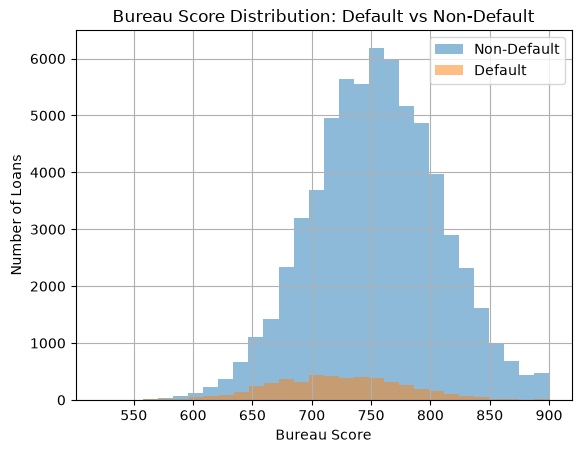

In [396]:
import matplotlib.pyplot as plt

model_data[
    model_data["DEFAULT_FLAG"] == 0
]["BUREAU_SCORE"].hist(
    bins=30,
    alpha=0.5,
    label="Non-Default"
)

model_data[
    model_data["DEFAULT_FLAG"] == 1
]["BUREAU_SCORE"].hist(
    bins=30,
    alpha=0.5,
    label="Default"
)

plt.xlabel("Bureau Score")
plt.ylabel("Number of Loans")
plt.title("Bureau Score Distribution: Default vs Non-Default")
plt.legend()
plt.show()

In [397]:
bureau_risk = model_data.groupby(
    pd.cut(model_data["BUREAU_SCORE"], bins=10),
    observed=False
)["DEFAULT_FLAG"].mean() * 100

bureau_risk

BUREAU_SCORE
(519.62, 558.0]    35.294118
(558.0, 596.0]     27.631579
(596.0, 634.0]     21.785335
(634.0, 672.0]     17.179295
(672.0, 710.0]     10.604915
(710.0, 748.0]      6.937772
(748.0, 786.0]      5.335968
(786.0, 824.0]      3.709583
(824.0, 862.0]      2.715299
(862.0, 900.0]      2.468354
Name: DEFAULT_FLAG, dtype: float64

In [ ]:
#As BUREAU_SCORE increases, observed default rate falls consistently:
#Around 35.3% in the lowest score band.
#Around 10.6% around 672–710.
#Around 5.3% around 748–786.
#Around 2.5% in the highest band.
#This is called a monotonic relationship: higher bureau score → progressively lower observed default rate. 
# That's economically intuitive and potentially useful for PD modelling

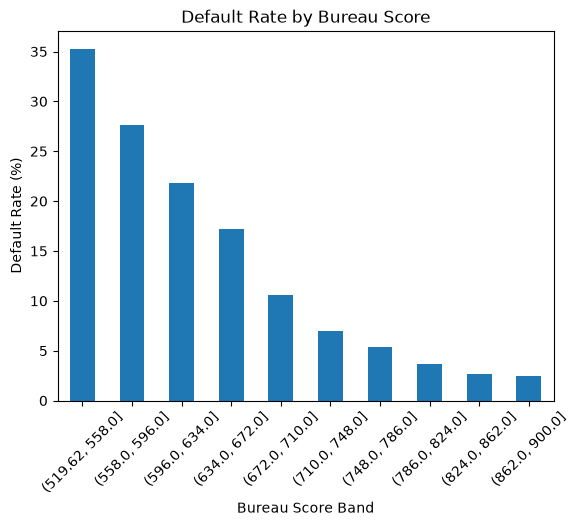

In [398]:
#credit-risk EDA
#The graph shows a strong, clean pattern: as Bureau Score increases, observed default rate decreases. 
# For our PD model, BUREAU_SCORE therefore looks like a promising predictor.
bureau_risk.plot(kind="bar")

plt.xlabel("Bureau Score Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Bureau Score")
plt.xticks(rotation=45)
plt.show()

In [399]:
#Examine FOIR because it measures how much of the borrower's income is already committed to monthly obligations. '
#Economically, we'd generally investigate whether higher repayment burden is associated with higher default risk.
#qcut(..., q=10) tries to put roughly 10% of borrowers into each band, 
#which makes comparing default rates across FOIR bands more meaningful during EDA.
#As FOIR rises, default rate generally rises from about 5.5% in the lowest FOIR group to 9.6% in the highest. 
#There are tiny fluctuations in the middle, but the overall trend is clear
foir_risk = model_data.groupby(
    pd.qcut(model_data["FOIR"], q=10, duplicates="drop"),
    observed=False
)["DEFAULT_FLAG"].mean() * 100

foir_risk

FOIR
(-0.0009, 0.0677]    5.509445
(0.0677, 0.104]      5.961209
(0.104, 0.136]       6.014930
(0.136, 0.168]       6.192792
(0.168, 0.203]       6.218656
(0.203, 0.242]       7.081668
(0.242, 0.288]       6.985083
(0.288, 0.347]       7.736308
(0.347, 0.436]       8.288005
(0.436, 0.94]        9.626128
Name: DEFAULT_FLAG, dtype: float64

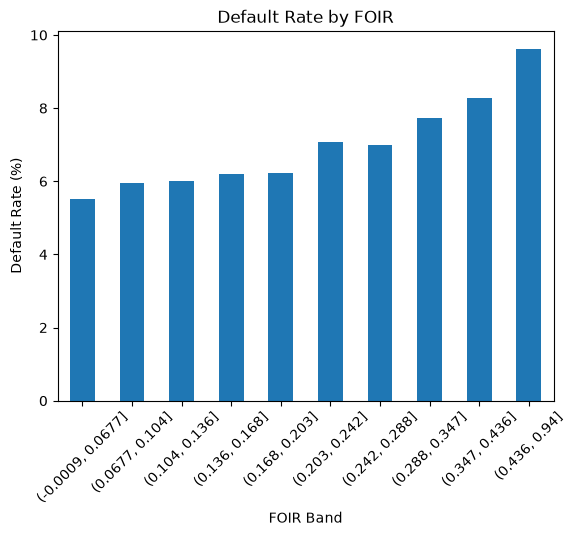

In [400]:
foir_risk.plot(kind="bar")

plt.xlabel("FOIR Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by FOIR")
plt.xticks(rotation=45)
plt.show()

In [401]:
#historical delinquency vs future default
#included count because higher delinquency counts may have very few customers. 
#A 30% default rate based on 20 customers means something quite different from 30% based on 5,000 customers.
delinq_risk = model_data.groupby(
    "DELINQUENCIES_12M"
)["DEFAULT_FLAG"].agg(["count", "mean"])

delinq_risk["default_rate"] = delinq_risk["mean"] * 100

delinq_risk

,count,mean,default_rate
DELINQUENCIES_12M,,,
0,52975,0.056347,5.634733
1,13122,0.093660,9.365950
2,2918,0.154901,15.490062
3,666,0.219219,21.921922
4,154,0.246753,24.675325
5,34,0.382353,38.235294
6,3,0.333333,33.333333
7,1,0.000000,0.000000


In [402]:
#PERSONAL_LOAN has a noticeably higher observed default rate in this dataset. But this doesn't mean loan type 
# itself causes default—personal-loan borrowers may differ in bureau score, income, collateral, leverage,
loan_type_risk = model_data.groupby(
    "LOAN_TYPE"
)["DEFAULT_FLAG"].agg(["count", "mean"])

loan_type_risk["default_rate"] = loan_type_risk["mean"] * 100

loan_type_risk

,count,mean,default_rate
LOAN_TYPE,,,
AUTO_LOAN,17461,0.060134,6.013401
HOME_LOAN,24363,0.062882,6.288224
OVERDRAFT_LOAN,6995,0.069764,6.976412
PERSONAL_LOAN,21054,0.085209,8.520946


In [403]:
#skewness of numeric variables
numeric_cols = model_data.select_dtypes(include="number").columns

skewness = model_data[numeric_cols].skew().sort_values(
    ascending=False
)

skewness
#WRITE_OFF_HISTORY = 36.6 is extremely skewed because almost everyone has 0 and only a tiny number have 1. 
# That's normal for a rare binary event; we don't log-transform it.
#OTHER_INCOME = 4.19 is strongly right-skewed because most customers have zero additional income
# and a smaller group has large values.
#Balances such as TOTAL_SECURED_BALANCE, TOTAL_OUTSTANDING, and TOTAL_UNSECURED_BALANCE are strongly right-skewed,
#  which is common in lending data.
#MONTHLY_INCOME = 2.85 and ANNUAL_INCOME = 2.85 are strongly skewed. 
# We already know annual income is exactly monthly income × 12, so eventually we should keep only one.
#BUREAU_SCORE ≈ -0.02 is almost symmetric.
#DEFAULT_FLAG appearing here isn't useful—we don't transform the target.
#PINCODE appearing as numeric is misleading. A PIN code is an identifier/category, not a continuous quantity,
#  so its numerical skewness has no modelling meaning.

WRITE_OFF_HISTORY           36.616524
OTHER_INCOME                 4.193739
TOTAL_SECURED_BALANCE        4.072298
TOTAL_OUTSTANDING            3.803395
TOTAL_UNSECURED_BALANCE      3.580821
EXISTING_EMI                 3.569941
DEFAULT_FLAG                 3.382403
TOTAL_MONTHLY_OBLIGATION     3.292478
MONTHLY_INCOME               2.854746
ANNUAL_INCOME                2.854746
DELINQUENCIES_12M            2.423072
REQUESTED_AMOUNT             2.327666
PROPERTY_VALUE               1.816621
LOAN_AMOUNT                  1.812247
COLLATERAL_VALUE             1.810275
CREDIT_CARD_LIMIT            1.380325
DTI                          1.240692
ENQUIRIES_3M                 1.205463
TENURE_MONTHS                0.995758
FOIR                         0.906530
ENQUIRIES_6M                 0.812761
PROPERTY_AGE_YEARS           0.784808
TOTAL_ACTIVE_LOANS           0.760454
EMPLOYMENT_TENURE_MONTHS     0.743830
CREDIT_CARD_UTILIZATION      0.522018
FRAUD_SCORE                  0.249311
OLDEST_TRADE

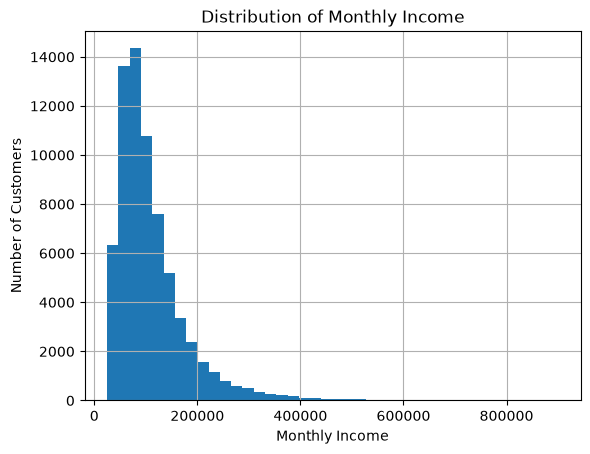

In [404]:
#visualize one important skewed predictor(monthly income)
model_data["MONTHLY_INCOME"].hist(bins=40)

plt.xlabel("Monthly Income")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Income")
plt.show()

#Most borrowers are concentrated roughly below ₹200k monthly income, while a relatively
#small number of high-income customers create the long tail extending toward ₹900k. 
#That's why we obtained skewness of about 2.85.

In [405]:
#Monthly Income vs default
#As customer income increases, does observed default risk change
income_risk = model_data.groupby(
    pd.qcut(model_data["MONTHLY_INCOME"], q=10, duplicates="drop"),
    observed=False
)["DEFAULT_FLAG"].mean() * 100

income_risk

MONTHLY_INCOME
(24999.999, 48189.2]    6.768746
(48189.2, 60084.2]      6.655217
(60084.2, 70275.6]      6.769715
(70275.6, 80559.0]      7.427018
(80559.0, 91799.0]      7.542579
(91799.0, 105367.2]     7.156147
(105367.2, 122437.4]    6.469157
(122437.4, 146966.4]    7.041649
(146966.4, 192692.0]    6.926159
(192692.0, 900000.0]    6.855589
Name: DEFAULT_FLAG, dtype: float64

In [406]:
# We are keeing Monthly Income and dropping Annual Income because they are perfectly correlated and gives the same output if we use either of them. So we will do * 12.
model_data = model_data.drop(columns=["ANNUAL_INCOME"])

model_data.shape

(69873, 60)

In [407]:
# As for predicting we don't need these columns, we will keep only the identifiers and target variable in a 
# separate dataframe for future use.
model_ids = model_data[
    ["LOAN_ACCOUNT_NO", "APPLICATION_ID", "CUSTOMER_ID"]
].copy()

In [408]:
model_data = model_data.drop(columns=[
    "LOAN_ACCOUNT_NO",
    "APPLICATION_ID",
    "CUSTOMER_ID"
])

model_data.shape

(69873, 57)

In [409]:
#Same for Application status as this feature is not useful for predicting default. 
model_data = model_data.drop(columns=["APPLICATION_STATUS"])

model_data.shape

(69873, 56)

In [ ]:
# Getting the Age of the application when the customer came from the DOB and the application date. 
# This will help us to understand the age of the customer when he/she applied for the loan. 
# This is an important feature as age can be a significant factor in credit risk assessment.
model_data["AGE_AT_APPLICATION"] = (
    (model_data["APPLICATION_DATE"] - model_data["DOB"]).dt.days / 365.25
)
model_data["AGE_AT_APPLICATION"].describe()

count    69873.000000
mean        37.321871
std          9.257154
min         17.686516
25%         30.795346
50%         37.237509
75%         43.608487
max         67.534565
Name: AGE_AT_APPLICATION, dtype: float64

In [411]:
#here is one issue we should investigate before dropping AGE or DOB
#(model_data["AGE_AT_APPLICATION"] < 18).sum()

In [413]:
#compare existing AGE with derived age
#(model_data["AGE"] - model_data["AGE_AT_APPLICATION"]).describe()

In [414]:
#existing AGE is on average about 1.8 years higher than AGE_AT_APPLICATION
#For an origination PD model, AGE_AT_APPLICATION is the appropriate variable because that's the
#age we would actually know when assessing the application.
#So we will drop the original AGE and DOB columns, keeping only AGE_AT_APPLICATION.
model_data = model_data.drop(columns=["AGE", "DOB"])
model_data.shape

(69873, 54)

In [415]:
#derive relationship tenure
#This can potentially capture whether a borrower is a new-to-bank customer versus an established customer.
model_data["CUSTOMER_TENURE_YEARS"] = (
    (model_data["APPLICATION_DATE"] - model_data["CUSTOMER_SINCE"]).dt.days
    / 365.25
)

model_data["CUSTOMER_TENURE_YEARS"].describe()

count    69873.000000
mean         3.282014
std          2.807729
min         -2.475017
25%          0.903491
50%          3.277207
75%          5.661875
max          9.032170
Name: CUSTOMER_TENURE_YEARS, dtype: float64

In [416]:
#A negative tenure means
#CUSTOMER_SINCE is later than APPLICATION_DATE
#Application: Jan 2024
#Customer since: Jan 2025
#which doesn't make business sense if CUSTOMER_SINCE truly means the date the customer relationship began.
(model_data["CUSTOMER_TENURE_YEARS"] < 0).sum()

np.int64(10777)

In [417]:
#We should not delete 10,777 customers, and we should not automatically change negative tenure to zero. 
#The safest choice for our first PD model is simply not to use this derived feature,
#because its source-date definition/data quality is questionable.
#10,777 out of 69,873 (~15.4%) have negative customer tenure.
model_data = model_data.drop(columns=["CUSTOMER_TENURE_YEARS"])

In [418]:
# The LOAN_PURPOSE and PRODUCT_CODE columns are redundant with LOAN_TYPE, so we will drop them to avoid multicollinearity and simplify the model.
model_data = model_data.drop(columns=[
    "LOAN_PURPOSE",
    "PRODUCT_CODE"
])

model_data.shape

(69873, 52)

In [419]:
#OLLATERAL_TYPE maps directly to loan type in this dataset:
model_data = model_data.drop(columns=["COLLATERAL_TYPE"])

model_data.shape

(69873, 51)

In [420]:
model_data.dtypes.value_counts()

str               18
float64           17
int64             13
datetime64[us]     3
Name: count, dtype: int64

In [421]:
#Identifying the datetime columns in the model_data dataframe as logistic regression models cannot handle datetime columns directly. We will need to convert these columns into numerical features or drop them if they are not useful for the model.
model_data.select_dtypes(include="datetime").columns.tolist()

['APPLICATION_DATE', 'CUSTOMER_SINCE', 'VALUATION_DATE']

In [422]:
application_dates = model_data["APPLICATION_DATE"].copy()

In [423]:
#earlier we found the application file contains only APPROVED and APPROVED_WITH_CONDITIONS —
#  no declined applications. Therefore, our current PD model is being developed on borrowers who actually 
# received loans. It cannot directly teach us the default behaviour of applicants the bank previously 
# declined because we don't observe loan performance for them
model_data = model_data.drop(columns=[
    "APPLICATION_DATE",
    "CUSTOMER_SINCE",
    "VALUATION_DATE"
])

model_data.shape

(69873, 48)

In [424]:
#application-date distribution by year
application_dates.dt.year.value_counts().sort_index()

APPLICATION_DATE
2023    11362
2024    34297
2025    24214
Name: count, dtype: int64

In [425]:
#train: 45,659 applications from 2023–2024
#Out-of-time test: 24,214 applications from 2025
train_mask = application_dates.dt.year <= 2024
test_mask = application_dates.dt.year == 2025

train_data = model_data[train_mask].copy()
test_data = model_data[test_mask].copy()

print("Train:", train_data.shape)
print("Test :", test_data.shape)

Train: (45659, 48)
Test : (24214, 48)


In [426]:
print("Train default rate:",
      train_data["DEFAULT_FLAG"].mean())

print("Test default rate:",
      test_data["DEFAULT_FLAG"].mean())

Train default rate: 0.07056659147156091
Test default rate: 0.067812009581234


In [427]:
X_train = train_data.drop(columns=["DEFAULT_FLAG"])
y_train = train_data["DEFAULT_FLAG"]

X_test = test_data.drop(columns=["DEFAULT_FLAG"])
y_test = test_data["DEFAULT_FLAG"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (45659, 47)
y_train: (45659,)
X_test : (24214, 47)
y_test : (24214,)


In [428]:
#Checking the Categorical and NUmeric columns
categorical_cols = X_train.select_dtypes(include="str").columns.tolist()
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical:", len(categorical_cols))
print("Numeric:", len(numeric_cols))
print("\nCategorical columns:")
print(categorical_cols)

Categorical: 18
Numeric: 29

Categorical columns:
['LOAN_TYPE', 'CHANNEL', 'BRANCH_ID', 'GENDER', 'MARITAL_STATUS', 'EDUCATION', 'OCCUPATION', 'EMPLOYMENT_TYPE', 'CITY', 'STATE', 'COMPANY_TYPE', 'DESIGNATION', 'INCOME_VERIFIED_FLAG', 'ADDRESS_VERIFIED', 'EMAIL_VERIFIED', 'PROPERTY_TYPE', 'PROPERTY_CITY', 'LEGAL_CLEARANCE_FLAG']


In [429]:
X_train[categorical_cols].nunique().sort_values(ascending=False)

BRANCH_ID               400
CITY                     28
PROPERTY_CITY            28
STATE                    12
PROPERTY_TYPE             9
COMPANY_TYPE              5
DESIGNATION               5
EDUCATION                 5
CHANNEL                   4
LOAN_TYPE                 4
EMPLOYMENT_TYPE           4
OCCUPATION                2
GENDER                    2
MARITAL_STATUS            2
ADDRESS_VERIFIED          2
INCOME_VERIFIED_FLAG      2
EMAIL_VERIFIED            2
LEGAL_CLEARANCE_FLAG      1
dtype: int64

In [430]:
#Dropping it because we don't need it 
X_train = X_train.drop(columns=[
    "BRANCH_ID",
    "LEGAL_CLEARANCE_FLAG"
])

X_test = X_test.drop(columns=[
    "BRANCH_ID",
    "LEGAL_CLEARANCE_FLAG"
])

print(X_train.shape)
print(X_test.shape)

(45659, 45)
(24214, 45)


In [431]:
#Numeric variables → missing values and scaling.
#Categorical variables → missing values and encoding.
categorical_cols = X_train.select_dtypes(include="str").columns.tolist()
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical:", len(categorical_cols))
print("Numeric:", len(numeric_cols))

Categorical: 16
Numeric: 29


In [432]:
X_train[numeric_cols].isnull().sum()[
    X_train[numeric_cols].isnull().sum() > 0
]

PROPERTY_VALUE        18320
COLLATERAL_VALUE      18320
LOAN_AMOUNT           18320
LTV                   18320
PROPERTY_AGE_YEARS    18320
dtype: int64

In [433]:
#we can fill these with 0, but only because LOAN_TYPE remains in the model and tells it whether the loan is secured/unsecured. 
# In this context, zero effectively represents “no applicable collateral information.”
collateral_numeric = [
    "PROPERTY_VALUE",
    "COLLATERAL_VALUE",
    "LOAN_AMOUNT",
    "LTV",
    "PROPERTY_AGE_YEARS"
]

X_train[collateral_numeric] = X_train[collateral_numeric].fillna(0)
X_test[collateral_numeric] = X_test[collateral_numeric].fillna(0)

In [434]:
X_train[numeric_cols].isnull().sum().sum()

np.int64(0)

In [435]:
#Categorical missing values
X_train[categorical_cols].isnull().sum()[
    X_train[categorical_cols].isnull().sum() > 0
]

PROPERTY_TYPE    18320
PROPERTY_CITY    18320
dtype: int64

In [436]:
#fill categorical missing values
X_train["PROPERTY_TYPE"] = X_train["PROPERTY_TYPE"].fillna("NOT_APPLICABLE")
X_train["PROPERTY_CITY"] = X_train["PROPERTY_CITY"].fillna("NOT_APPLICABLE")

X_test["PROPERTY_TYPE"] = X_test["PROPERTY_TYPE"].fillna("NOT_APPLICABLE")
X_test["PROPERTY_CITY"] = X_test["PROPERTY_CITY"].fillna("NOT_APPLICABLE")

In [437]:
X_train.isnull().sum().sum()

np.int64(0)

In [438]:
#One hot encoding categorical variables.
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True
)

In [439]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(45659, 131)
(24214, 131)


In [440]:
#True confirms the train and OOT datasets have exactly the same encoded columns in the same order.
(X_train_encoded.columns == X_test_encoded.columns).all()

np.True_

In [441]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [ ]:
print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded :", X_test_encoded.shape)

print(
    "Same columns:",
    (X_train_encoded.columns == X_test_encoded.columns).all()
)

print("Missing train:", X_train_encoded.isnull().sum().sum())
print("Missing test :", X_test_encoded.isnull().sum().sum())

In [447]:
X_train_encoded[numeric_cols] = scaler.fit_transform(
    X_train_encoded[numeric_cols]
)

X_test_encoded[numeric_cols] = scaler.transform(
    X_test_encoded[numeric_cols]
)

In [448]:
# Adding baseline Logistics regression
from sklearn.linear_model import LogisticRegression

pd_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

pd_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [449]:
print("Model trained successfully")

Model trained successfully


In [ ]:
#Why [:, 1]? predict_proba() gives two probabilities for each customer:
train_pd = pd_model.predict_proba(X_train_encoded)[:, 1]
test_pd = pd_model.predict_proba(X_test_encoded)[:, 1]
#numnbers would be between 0 and 1, representing the predicted probability of default for each customer.

In [ ]:
#Out put test the fourth observation has a predicted PD of about 17.0%, 
# while the eighth is about 2.7%.
test_pd[:10]

array([0.07207154, 0.04047263, 0.15895284, 0.17014386, 0.06846733,
       0.02893663, 0.12732181, 0.02686034, 0.0830871 , 0.05600979])

In [ ]:
#model is showing meaningful discrimination and isn't collapsing on the later 2025 population.
#  We should not call it production-ready yet—AUC is only one part of PD validation
from sklearn.metrics import roc_auc_score

train_auc = roc_auc_score(y_train, train_pd)
test_auc = roc_auc_score(y_test, test_pd)

print("Train AUC:", round(train_auc, 4))
print("OOT Test AUC:", round(test_auc, 4))
#In credit-risk terminology, we can also express AUC as Gini:
#Gini = 2 \times AUC - 1 = 2(0.6734)-1= 0.3468, or about 34.68% for the OOT test set.

Train AUC: 0.6833
OOT Test AUC: 0.6734


In [ ]:
#It tells us how well the model separates the default and non-default populations.
#Our model gives every applicant a PD. Ideally:
#Defaulters should tend to receive higher PDs
#Non-defaulters should tend to receive lower PDs
#imagine sorting customers from highest PD to lowest PD. 
# At some cutoff we might have captured:
#70% of all actual defaulters but only 35% of all non-defaulters
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, test_pd)

ks = max(tpr - fpr)

print("OOT KS:", round(ks, 4))
print("OOT KS %:", round(ks * 100, 2))


OOT KS: 0.2506
OOT KS %: 25.06


In [ ]:
#example, if actual default rate is around 6.8% but average predicted PD is 15%, the model may
# rank customers  reasonably well while its probability estimates are poorly calibrated.
print("Actual OOT default rate :", round(y_test.mean(), 4))
print("Average predicted PD    :", round(test_pd.mean(), 4))

Actual OOT default rate : 0.0678
Average predicted PD    : 0.0712


In [ ]:
# We are doing this to undertand that if model predicts a PD of 15% for a group of customers, 
# then we would expect about 15% of them to actually default.
calibration_df = pd.DataFrame({
    "Actual_Default": y_test.values,
    "Predicted_PD": test_pd
})

calibration_df["PD_Decile"] = pd.qcut(
    calibration_df["Predicted_PD"],
    10,
    duplicates="drop"
)

calibration_table = calibration_df.groupby(
    "PD_Decile",
    observed=True
).agg(
    Customers=("Actual_Default", "count"),
    Average_PD=("Predicted_PD", "mean"),
    Actual_Default_Rate=("Actual_Default", "mean")
)

calibration_table

,Customers,Average_PD,Actual_Default_Rate
PD_Decile,,,
"(0.00524, 0.0272]",2422,0.021511,0.024773
"(0.0272, 0.0349]",2421,0.031184,0.025196
"(0.0349, 0.0421]",2421,0.038535,0.042544
"(0.0421, 0.0494]",2422,0.045755,0.039224
"(0.0494, 0.0575]",2421,0.053318,0.056175
"(0.0575, 0.0671]",2421,0.062018,0.068567
"(0.0671, 0.0795]",2422,0.072794,0.063997
"(0.0795, 0.0974]",2421,0.087687,0.084676
"(0.0974, 0.132]",2421,0.112305,0.102024


In [ ]:
#we have already established that the model has some discriminatory power and broadly sensible 
#calibration. But imagine presenting this model to a bank's credit-risk team
#based on our earlier EDA, we'd expect something like higher bureau score → lower default risk.
#If the fitted model showed something completely unexpected, we'd want to investigate before trusting it.

In [ ]:
#This simply pairs the 131 feature names with the 131 coefficients learned by logistic regression.
coef_table = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Coefficient": pd_model.coef_[0]
}) 

#We create the absolute size because -0.40 and +0.40 have the same magnitude
#even though they move risk in opposite directions.

coef_table["Abs_Coefficient"] = coef_table["Coefficient"].abs()

# This brings the largest coefficients to the top so we don't have to inspect all 131 features.
coef_table = coef_table.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coef_table.head(20)
#-ve sign means As bureau score increases, the model tends to reduce PD, holding the other variables constant.

,Feature,Coefficient,Abs_Coefficient
44,EMPLOYMENT_TYPE_SELF_EMPLOYED,-0.857190,0.857190
41,OCCUPATION_EMPLOYEE,-0.730390,0.730390
94,PROPERTY_TYPE_EV,-0.508582,0.508582
6,BUREAU_SCORE,-0.498030,0.498030
95,PROPERTY_TYPE_HATCHBACK,-0.356780,0.356780
114,PROPERTY_CITY_JODHPUR,-0.353767,0.353767
17,TOTAL_MONTHLY_OBLIGATION,-0.331018,0.331018
104,PROPERTY_CITY_BHUBANESWAR,-0.329357,0.329357
101,PROPERTY_TYPE_SUV,-0.304845,0.304845
16,EXISTING_EMI,0.290776,0.290776


In [ ]:
#we standardized the numeric variables before training, 
# their coefficients are also somewhat easier to compare.
#It removes catrgotical variables and focuses on numeric features, 
# which are often more interpretable in credit-risk models.
numeric_coef = coef_table[
    coef_table["Feature"].isin(numeric_cols)
].copy()

numeric_coef = numeric_coef.sort_values(
    "Abs_Coefficient",
    ascending=False
)

numeric_coef[["Feature", "Coefficient"]]

,Feature,Coefficient
6,BUREAU_SCORE,-0.498030
17,TOTAL_MONTHLY_OBLIGATION,-0.331018
16,EXISTING_EMI,0.290776
13,DELINQUENCIES_12M,0.163078
21,FOIR,0.152968
12,ENQUIRIES_6M,0.100167
0,REQUESTED_AMOUNT,-0.098559
19,TOTAL_UNSECURED_BALANCE,0.090864
27,LTV,0.078055
25,COLLATERAL_VALUE,0.066823


In [ ]:
#We shouldn't be treating PINCODE as a continuous number.
#A PIN code is actually a location identifier, not a quantity. We already have CITY and STATE, 
# so for this first model I would simply remove PINCODE rather than create hundreds/thousands 
# of additional dummy variables.
#Our strongest continuous driver, BUREAU_SCORE, is behaving exactly as expected.
X_train_encoded = X_train_encoded.drop(columns=["PINCODE"])
X_test_encoded = X_test_encoded.drop(columns=["PINCODE"])

In [459]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(45659, 130)
(24214, 130)


In [ ]:
#- EXISTING_EMI = ₹20,000
#TOTAL_MONTHLY_OBLIGATION = ₹25,000
#When both are given to logistic regression alongside FOIR, income, etc.,
#  the model has to decide how to distribute the effect among them. That can sometimes produce:
#one coefficient positive, another negative

In [460]:
X_train[
    ["EXISTING_EMI", "TOTAL_MONTHLY_OBLIGATION", "FOIR"]
].corr()

,EXISTING_EMI,TOTAL_MONTHLY_OBLIGATION,FOIR
EXISTING_EMI,1.000000,0.973894,0.638466
TOTAL_MONTHLY_OBLIGATION,0.973894,1.000000,0.635290
FOIR,0.638466,0.635290,1.000000


In [ ]:
#for example, EXISTING_EMI and TOTAL_MONTHLY_OBLIGATION have correlation near 0.9, they are
#carrying very similar information and we may consider keeping only the more meaningful variable.
#If the correlation is low/moderate, then we'll investigate differently rather than dropping anything.

In [ ]:
#To reduce redundant information and make our logistic model more stable and interpretable.
X_train_encoded = X_train_encoded.drop(
    columns=["EXISTING_EMI"]
)

X_test_encoded = X_test_encoded.drop(
    columns=["EXISTING_EMI"]
)

In [462]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(45659, 129)
(24214, 129)


In [463]:
#if PROPERTY_VALUE and COLLATERAL_VALUE are extremely correlated (for example ~0.99), we'll 
# probably keep the more relevant collateral value and remove property value.
X_train[
    ["PROPERTY_VALUE", "COLLATERAL_VALUE", "LOAN_AMOUNT", "LTV"]
].corr()

,PROPERTY_VALUE,COLLATERAL_VALUE,LOAN_AMOUNT,LTV
PROPERTY_VALUE,1.000000,0.999606,0.981389,0.487767
COLLATERAL_VALUE,0.999606,1.000000,0.981768,0.488158
LOAN_AMOUNT,0.981389,0.981768,1.000000,0.529780
LTV,0.487767,0.488158,0.529780,1.000000


In [464]:
# Due to the high collateral value and property value correlation, we will drop the PROPERTY_VALUE and LOAN_AMOUNT columns to avoid multicollinearity and simplify the model.
X_train_encoded = X_train_encoded.drop(
    columns=["PROPERTY_VALUE", "LOAN_AMOUNT"]
)

X_test_encoded = X_test_encoded.drop(
    columns=["PROPERTY_VALUE", "LOAN_AMOUNT"]
)

In [465]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(45659, 127)
(24214, 127)


In [466]:
# Now we will retrain the model with the new features
pd_model_clean = LogisticRegression(
    max_iter=1000,
    random_state=42
)

pd_model_clean.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [467]:
train_pd_clean = pd_model_clean.predict_proba(
    X_train_encoded
)[:, 1]

test_pd_clean = pd_model_clean.predict_proba(
    X_test_encoded
)[:, 1]

In [ ]:
#The original model was using 131 predictors. After removing some redundant/inappropriate 
# information, we have 127 predictors and effectively identical OOT AUC.
train_auc_clean = roc_auc_score(
    y_train,
    train_pd_clean
)

test_auc_clean = roc_auc_score(
    y_test,
    test_pd_clean
)

print("Clean Model Train AUC:", round(train_auc_clean, 4))
print("Clean Model OOT AUC  :", round(test_auc_clean, 4))

Clean Model Train AUC: 0.6828
Clean Model OOT AUC  : 0.6734


In [469]:
#We removed EXISTING_EMI, which was 97.4% correlated with obligations. Now we want to see what 
# coefficient the model assigns to TOTAL_MONTHLY_OBLIGATION
clean_coef = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Coefficient": pd_model_clean.coef_[0]
})

clean_coef[
    clean_coef["Feature"].isin([
        "BUREAU_SCORE",
        "TOTAL_MONTHLY_OBLIGATION",
        "FOIR",
        "DELINQUENCIES_12M",
        "MONTHLY_INCOME",
        "DTI",
        "CREDIT_CARD_UTILIZATION",
        "LTV"
    ])
]

,Feature,Coefficient
2,MONTHLY_INCOME,-0.044969
5,BUREAU_SCORE,-0.497078
9,CREDIT_CARD_UTILIZATION,0.002022
12,DELINQUENCIES_12M,0.164299
15,TOTAL_MONTHLY_OBLIGATION,-0.026624
18,DTI,0.039081
19,FOIR,0.161051
23,LTV,0.063228


In [470]:
pd_model_clean

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [471]:
print(
    "Actual OOT Default Rate:",
    round(y_test.mean() * 100, 2),
    "%"
)

print(
    "Average Predicted PD:",
    round(test_pd_clean.mean() * 100, 2),
    "%"
)

Actual OOT Default Rate: 6.78 %
Average Predicted PD: 7.13 %


In [472]:
final_features = X_train_encoded.columns.tolist()

print("Number of final features:", len(final_features))

Number of final features: 127


In [475]:
import pickle

with open("models/pd_model_v1.pkl", "wb") as file:
    pickle.dump(pd_model_clean, file)

print("PD Model V1 saved successfully")

PD Model V1 saved successfully


In [ ]:
#The scaler learned the mean and standard deviation from the training population.
#When a brand-new applicant arrives, we must transform their values using exactly the 
#same training-data scaler. We must not calculate a new scaler for the applicant.
with open("models/scaler_v1.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Scaler V1 saved successfully")

Scaler V1 saved successfully


In [477]:
#Our model expects exactly 127 columns in the same names/order used during training. 
# A new applicant will initially have perhaps 30–40 raw fields, not 127 encoded fields
with open("models/final_features_v1.pkl", "wb") as file:
    pickle.dump(final_features, file)

print("Final feature list saved successfully")
print("Features saved:", len(final_features))

Final feature list saved successfully
Features saved: 127


In [478]:
#We're not changing the model here. We're documenting its preprocessing correctly 
# so that a future applicant goes through exactly the same process as the training customers.
final_numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

print("Final numeric features:", len(final_numeric_cols))
print(final_numeric_cols)

Final numeric features: 25
['REQUESTED_AMOUNT', 'TENURE_MONTHS', 'MONTHLY_INCOME', 'EMPLOYMENT_TENURE_MONTHS', 'OTHER_INCOME', 'BUREAU_SCORE', 'TOTAL_ACTIVE_LOANS', 'TOTAL_OUTSTANDING', 'CREDIT_CARD_LIMIT', 'CREDIT_CARD_UTILIZATION', 'ENQUIRIES_3M', 'ENQUIRIES_6M', 'DELINQUENCIES_12M', 'WRITE_OFF_HISTORY', 'OLDEST_TRADE_MONTHS', 'TOTAL_MONTHLY_OBLIGATION', 'TOTAL_SECURED_BALANCE', 'TOTAL_UNSECURED_BALANCE', 'DTI', 'FOIR', 'FRAUD_SCORE', 'DEVICE_RISK_SCORE', 'COLLATERAL_VALUE', 'LTV', 'PROPERTY_AGE_YEARS']


In [ ]:
#The cleanest fix is to create a new scaler specifically for the 25 final numeric features,
#then retrain the final model using that clean preprocessing. This avoids a fragile prediction function later
# Scaling for the numerical features 
final_scaler = StandardScaler()

X_train_encoded[final_numeric_cols] = final_scaler.fit_transform(
    X_train[final_numeric_cols]
)

X_test_encoded[final_numeric_cols] = final_scaler.transform(
    X_test[final_numeric_cols]
)

In [480]:
pd_model_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

pd_model_final.fit(
    X_train_encoded,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [481]:
test_pd_final = pd_model_final.predict_proba(
    X_test_encoded
)[:, 1]

In [482]:
final_auc = roc_auc_score(
    y_test,
    test_pd_final
)

print("Final OOT AUC:", round(final_auc, 4))
print(
    "Average Predicted PD:",
    round(test_pd_final.mean() * 100, 2),
    "%"
)

Final OOT AUC: 0.6734
Average Predicted PD: 7.13 %


In [ ]:
#save the final versions
with open("models/pd_model_v1.pkl", "wb") as file:
    pickle.dump(pd_model_final, file)

with open("models/scaler_v1.pkl", "wb") as file:
    pickle.dump(final_scaler, file)

with open("models/final_numeric_cols_v1.pkl", "wb") as file:
    pickle.dump(final_numeric_cols, file)

print("Final PD Model V1 saved")
print("Final scaler saved")
print("Final numeric feature list saved")

Final PD Model V1 saved
Final scaler saved
Final numeric feature list saved


In [ ]:
#The 127 features contain many one-hot columns such as CITY_DELHI, but a user should never 
#have to enter 127 values.
final_categorical_cols = [
    col for col in categorical_cols
    if col in X_train.columns
]

print("Categorical fields:", len(final_categorical_cols))
print(final_categorical_cols)

Categorical fields: 16
['LOAN_TYPE', 'CHANNEL', 'GENDER', 'MARITAL_STATUS', 'EDUCATION', 'OCCUPATION', 'EMPLOYMENT_TYPE', 'CITY', 'STATE', 'COMPANY_TYPE', 'DESIGNATION', 'INCOME_VERIFIED_FLAG', 'ADDRESS_VERIFIED', 'EMAIL_VERIFIED', 'PROPERTY_TYPE', 'PROPERTY_CITY']


In [485]:
with open("models/final_categorical_cols_v1.pkl", "wb") as file:
    pickle.dump(final_categorical_cols, file)

print("Final categorical feature list saved")

Final categorical feature list saved


In [486]:
sample_customer = X_test.iloc[[0]].copy()

sample_customer

,LOAN_TYPE,REQUESTED_AMOUNT,TENURE_MONTHS,CHANNEL,GENDER,MARITAL_STATUS,EDUCATION,OCCUPATION,EMPLOYMENT_TYPE,CITY,...,EMAIL_VERIFIED,FRAUD_SCORE,DEVICE_RISK_SCORE,PROPERTY_TYPE,PROPERTY_VALUE,COLLATERAL_VALUE,LOAN_AMOUNT,LTV,PROPERTY_CITY,PROPERTY_AGE_YEARS
0,PERSONAL_LOAN,422000.0,36,BRANCH,F,SINGLE,DIPLOMA,EMPLOYEE,SALARIED,DELHI,...,Y,122,59,NOT_APPLICABLE,0.0,0.0,0.0,0.0,NOT_APPLICABLE,0.0


In [487]:
test_pd_final[0]

np.float64(0.07061009777097531)

In [488]:
print(
    "Existing model PD:",
    round(test_pd_final[0] * 100, 2),
    "%"
)

Existing model PD: 7.06 %


In [490]:
def predict_pd(applicant):

    # Make a copy so we don't modify the original data
    data = applicant.copy()

    # Structural missing values for unsecured loans
    collateral_numeric = [
        "COLLATERAL_VALUE",
        "LTV",
        "PROPERTY_AGE_YEARS"
    ]

    data[collateral_numeric] = data[collateral_numeric].fillna(0)

    data["PROPERTY_TYPE"] = data["PROPERTY_TYPE"].fillna(
        "NOT_APPLICABLE"
    )

    data["PROPERTY_CITY"] = data["PROPERTY_CITY"].fillna(
        "NOT_APPLICABLE"
    )

    # Scale the 25 numeric variables
    data[final_numeric_cols] = final_scaler.transform(
        data[final_numeric_cols]
    )

    # One-hot encode categorical variables
    data = pd.get_dummies(
        data,
        columns=final_categorical_cols,
        drop_first=True
    )

    # Make columns exactly match the 127 model features
    data = data.reindex(
        columns=final_features,
        fill_value=False
    )

    # Predict probability of default
    pd_probability = pd_model_final.predict_proba(data)[:, 1]

    return pd_probability[0]

In [ ]:
#Prediction is not matching with the actual
new_function_pd = predict_pd(sample_customer)

print(
    "Prediction function PD:",
    round(new_function_pd * 100, 2),
    "%"
)

print(
    "Original model PD:",
    round(test_pd_final[0] * 100, 2),
    "%"
)

Prediction function PD: 17.3 %
Original model PD: 7.06 %


In [ ]:
#comparing and checking
data_check = sample_customer.copy()

collateral_numeric = [
    "COLLATERAL_VALUE",
    "LTV",
    "PROPERTY_AGE_YEARS"
]

data_check[collateral_numeric] = (
    data_check[collateral_numeric].fillna(0)
)

data_check["PROPERTY_TYPE"] = (
    data_check["PROPERTY_TYPE"].fillna("NOT_APPLICABLE")
)

data_check["PROPERTY_CITY"] = (
    data_check["PROPERTY_CITY"].fillna("NOT_APPLICABLE")
)

data_check[final_numeric_cols] = final_scaler.transform(
    data_check[final_numeric_cols]
)

data_check = pd.get_dummies(
    data_check,
    columns=final_categorical_cols,
    drop_first=True
)

data_check = data_check.reindex(
    columns=final_features,
    fill_value=False
)

In [ ]:
#checking columns which are available for the sample customer but not in the final features and vice versa.
different_cols = [
    col for col in final_features
    if X_test_encoded.iloc[0][col] != data_check.iloc[0][col]
]

print("Number of different columns:", len(different_cols))
print(different_cols)

Number of different columns: 12
['LOAN_TYPE_PERSONAL_LOAN', 'MARITAL_STATUS_SINGLE', 'OCCUPATION_EMPLOYEE', 'EMPLOYMENT_TYPE_SALARIED', 'CITY_DELHI', 'COMPANY_TYPE_SME', 'DESIGNATION_MANAGER', 'INCOME_VERIFIED_FLAG_Y', 'ADDRESS_VERIFIED_Y', 'EMAIL_VERIFIED_Y', 'PROPERTY_TYPE_NOT_APPLICABLE', 'PROPERTY_CITY_NOT_APPLICABLE']


In [498]:
def predict_pd(applicant):

    data = applicant.copy()

    # Handle structural collateral missing values
    collateral_numeric = [
        "COLLATERAL_VALUE",
        "LTV",
        "PROPERTY_AGE_YEARS"
    ]

    data[collateral_numeric] = (
        data[collateral_numeric].fillna(0)
    )

    data["PROPERTY_TYPE"] = (
        data["PROPERTY_TYPE"].fillna("NOT_APPLICABLE")
    )

    data["PROPERTY_CITY"] = (
        data["PROPERTY_CITY"].fillna("NOT_APPLICABLE")
    )

    # Create empty final model input
    model_input = pd.DataFrame(
        0.0,
        index=data.index,
        columns=final_features
    )

    # Scale numeric variables
    scaled_numeric = final_scaler.transform(
        data[final_numeric_cols]
    )

    model_input[final_numeric_cols] = scaled_numeric

    # Manually create categorical dummy values
    for col in final_categorical_cols:

        value = data.iloc[0][col]

        dummy_col = f"{col}_{value}"

        if dummy_col in final_features:
            model_input[dummy_col] = 1.0

    # Predict PD
    pd_probability = pd_model_final.predict_proba(
        model_input
    )[:, 1]

    return pd_probability[0]

In [499]:
new_function_pd = predict_pd(sample_customer)

print(
    "Prediction function PD:",
    round(new_function_pd * 100, 2),
    "%"
)

print(
    "Original model PD:",
    round(test_pd_final[0] * 100, 2),
    "%"
)

Prediction function PD: 7.06 %
Original model PD: 7.06 %


In [ ]:
#what went wrong is LOAN_TYPE = PERSONAL_LOAN ,CITY = DELHI
# needs to become LOAN_TYPE_PERSONAL_LOAN = 1 ,CITY_DELHI = 1
#But our first prediction function made a mistake and converted some of those to:
# LOAN_TYPE_PERSONAL_LOAN = 0  ,CITY_DELHI = 0          

In [500]:
sample_customer.iloc[0].to_dict()

{'LOAN_TYPE': 'PERSONAL_LOAN',
 'REQUESTED_AMOUNT': 422000.0,
 'TENURE_MONTHS': 36,
 'CHANNEL': 'BRANCH',
 'GENDER': 'F',
 'MARITAL_STATUS': 'SINGLE',
 'EDUCATION': 'DIPLOMA',
 'OCCUPATION': 'EMPLOYEE',
 'EMPLOYMENT_TYPE': 'SALARIED',
 'CITY': 'DELHI',
 'STATE': 'DL',
 'PINCODE': 449681,
 'MONTHLY_INCOME': 143139.0,
 'EMPLOYMENT_TENURE_MONTHS': 191,
 'COMPANY_TYPE': 'SME',
 'DESIGNATION': 'MANAGER',
 'OTHER_INCOME': 0.0,
 'INCOME_VERIFIED_FLAG': 'Y',
 'BUREAU_SCORE': 740,
 'TOTAL_ACTIVE_LOANS': 3,
 'TOTAL_OUTSTANDING': 2347894.0,
 'CREDIT_CARD_LIMIT': 354221.0,
 'CREDIT_CARD_UTILIZATION': 0.402,
 'ENQUIRIES_3M': 2,
 'ENQUIRIES_6M': 4,
 'DELINQUENCIES_12M': 0,
 'WRITE_OFF_HISTORY': 0,
 'OLDEST_TRADE_MONTHS': 106,
 'EXISTING_EMI': 9256.0,
 'TOTAL_MONTHLY_OBLIGATION': 16376.0,
 'TOTAL_SECURED_BALANCE': 507422.18,
 'TOTAL_UNSECURED_BALANCE': 237025.12,
 'DTI': 2.0684,
 'FOIR': 0.1144,
 'ADDRESS_VERIFIED': 'Y',
 'EMAIL_VERIFIED': 'Y',
 'FRAUD_SCORE': 122,
 'DEVICE_RISK_SCORE': 59,
 'PROPERT

In [501]:
simple_features = [
    "REQUESTED_AMOUNT",
    "TENURE_MONTHS",
    "MONTHLY_INCOME",
    "TOTAL_MONTHLY_OBLIGATION",
    "BUREAU_SCORE",
    "EMPLOYMENT_TYPE",
    "EMPLOYMENT_TENURE_MONTHS",
    "DELINQUENCIES_12M"
]

print("Number of user inputs:", len(simple_features))
print(simple_features)

Number of user inputs: 8
['REQUESTED_AMOUNT', 'TENURE_MONTHS', 'MONTHLY_INCOME', 'TOTAL_MONTHLY_OBLIGATION', 'BUREAU_SCORE', 'EMPLOYMENT_TYPE', 'EMPLOYMENT_TENURE_MONTHS', 'DELINQUENCIES_12M']


In [502]:
X_train_simple = X_train[simple_features].copy()
X_test_simple = X_test[simple_features].copy()

print("Training shape:", X_train_simple.shape)
print("Test shape:", X_test_simple.shape)

Training shape: (45659, 8)
Test shape: (24214, 8)


In [503]:
X_train_simple["FOIR_CALCULATED"] = (
    X_train_simple["TOTAL_MONTHLY_OBLIGATION"]
    / X_train_simple["MONTHLY_INCOME"]
)

X_test_simple["FOIR_CALCULATED"] = (
    X_test_simple["TOTAL_MONTHLY_OBLIGATION"]
    / X_test_simple["MONTHLY_INCOME"]
)

print("Training shape:", X_train_simple.shape)
print("Test shape:", X_test_simple.shape)

print(
    X_train_simple[
        [
            "MONTHLY_INCOME",
            "TOTAL_MONTHLY_OBLIGATION",
            "FOIR_CALCULATED"
        ]
    ].head()
)

Training shape: (45659, 9)
Test shape: (24214, 9)
   MONTHLY_INCOME  TOTAL_MONTHLY_OBLIGATION  FOIR_CALCULATED
1        148716.0                   30063.0         0.202150
3        195077.0                   60918.0         0.312277
5        175487.0                   46172.0         0.263108
6        103163.0                   12941.0         0.125442
7         68033.0                   15237.0         0.223965


In [504]:
X_train_simple = pd.get_dummies(
    X_train_simple,
    columns=["EMPLOYMENT_TYPE"],
    drop_first=True
)

X_test_simple = pd.get_dummies(
    X_test_simple,
    columns=["EMPLOYMENT_TYPE"],
    drop_first=True
)

X_test_simple = X_test_simple.reindex(
    columns=X_train_simple.columns,
    fill_value=0
)

print("Training shape:", X_train_simple.shape)
print("Test shape:", X_test_simple.shape)

print(X_train_simple.columns.tolist())

Training shape: (45659, 11)
Test shape: (24214, 11)
['REQUESTED_AMOUNT', 'TENURE_MONTHS', 'MONTHLY_INCOME', 'TOTAL_MONTHLY_OBLIGATION', 'BUREAU_SCORE', 'EMPLOYMENT_TENURE_MONTHS', 'DELINQUENCIES_12M', 'FOIR_CALCULATED', 'EMPLOYMENT_TYPE_PROFESSIONAL', 'EMPLOYMENT_TYPE_SALARIED', 'EMPLOYMENT_TYPE_SELF_EMPLOYED']


In [505]:
from sklearn.preprocessing import StandardScaler

simple_numeric_cols = [
    "REQUESTED_AMOUNT",
    "TENURE_MONTHS",
    "MONTHLY_INCOME",
    "TOTAL_MONTHLY_OBLIGATION",
    "BUREAU_SCORE",
    "EMPLOYMENT_TENURE_MONTHS",
    "DELINQUENCIES_12M",
    "FOIR_CALCULATED"
]

simple_scaler = StandardScaler()

X_train_simple[simple_numeric_cols] = (
    simple_scaler.fit_transform(
        X_train_simple[simple_numeric_cols]
    )
)

X_test_simple[simple_numeric_cols] = (
    simple_scaler.transform(
        X_test_simple[simple_numeric_cols]
    )
)

print("Scaling complete")
print("Final model columns:", X_train_simple.shape[1])

Scaling complete
Final model columns: 11


In [506]:
from sklearn.linear_model import LogisticRegression

simple_pd_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

simple_pd_model.fit(
    X_train_simple,
    y_train
)

print("Simplified PD model trained successfully")

Simplified PD model trained successfully


In [507]:
from sklearn.metrics import roc_auc_score

test_pd_simple = simple_pd_model.predict_proba(
    X_test_simple
)[:, 1]

simple_auc = roc_auc_score(
    y_test,
    test_pd_simple
)

print("Full Model OOT AUC:       0.6734")
print("Simplified Model OOT AUC:", round(simple_auc, 4))

Full Model OOT AUC:       0.6734
Simplified Model OOT AUC: 0.676


In [508]:
import pickle

with open("models/simple_pd_model_v1.pkl", "wb") as file:
    pickle.dump(simple_pd_model, file)

with open("models/simple_scaler_v1.pkl", "wb") as file:
    pickle.dump(simple_scaler, file)

with open("models/simple_features_v1.pkl", "wb") as file:
    pickle.dump(X_train_simple.columns.tolist(), file)

with open("models/simple_numeric_cols_v1.pkl", "wb") as file:
    pickle.dump(simple_numeric_cols, file)

print("Simplified model files saved successfully")

Simplified model files saved successfully


In [509]:
print(
    "Actual OOT Default Rate:",
    round(y_test.mean() * 100, 2),
    "%"
)

print(
    "Full Model Average PD:",
    round(test_pd_final.mean() * 100, 2),
    "%"
)

print(
    "Simple Model Average PD:",
    round(test_pd_simple.mean() * 100, 2),
    "%"
)

Actual OOT Default Rate: 6.78 %
Full Model Average PD: 7.13 %
Simple Model Average PD: 7.11 %
